# Imports & functions

In [1]:
import glob, os, re
import samnet as st
from samnet.sampling import *
from samnet.metrics import *
import random
import inspect
import networkx as nx
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
from collections import deque
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
import scipy.spatial.distance as sp_dist
from typing import Union, Optional, Dict
from itertools import cycle

In [2]:
def nonlinear_barabasi_albert_graph(n, m, alpha, seed=None):

    if seed is not None:
        np.random.seed(seed)
    if m < 1 or m >= n:
        raise nx.NetworkXError("Barabási–Albert network must have m >= 1 and m < n")

    G = nx.complete_graph(m)

    target_nodes = list(range(m))
    repeated_nodes = []

    for source in range(m, n):
        probs = np.array([G.degree(node)**alpha for node in target_nodes], dtype=np.float64)
        norm_probs = probs / probs.sum()
        new_edges = np.random.choice(target_nodes, size=m, replace=False, p=norm_probs)
        G.add_edges_from(zip([source] * m, new_edges))
        target_nodes.append(source)
        repeated_nodes.extend(new_edges)
        repeated_nodes.extend([source] * m)

    return G

In [3]:
def calculate_dispersion_distance(df):

    mean_dist = []
    var_dist = []
    methods = []
    graphs = []
    sizes = []

    #doesn't count the original net
    for method in df['sampling_method'].unique()[1:]: 
        swp = df.loc[df['sampling_method'] == method]
        for size in swp['sample_size'].unique():
            swp2 = swp.loc[swp['sample_size'] == size]
            for graph in swp2['graph_id'].unique():    
                pca_1 =  swp2.loc[swp2['graph_id'] == graph]['pca_component_1'].values
                pca_2 =  swp2.loc[swp2['graph_id'] == graph]['pca_component_2'].values
                pca_3 =  swp2.loc[swp2['graph_id'] == graph]['pca_component_2'].values

                #original data: extracts it and then repeats n=len(pca_1) times
                orig_pca_1 = np.repeat(df.loc[df['sampling_method'] == 'Original'].loc[df['graph_id'] == 0]['pca_component_1'].values[0], len(pca_1))
                orig_pca_2 = np.repeat(df.loc[df['sampling_method'] == 'Original'].loc[df['graph_id'] == 0]['pca_component_2'].values[0], len(pca_2))
                orig_pca_3 = np.repeat(df.loc[df['sampling_method'] == 'Original'].loc[df['graph_id'] == 0]['pca_component_3'].values[0], len(pca_3))

                #perform the calculation d = sqrt( sum_i( (ci_orig - ci_sample)^2 ) )

                distance = np.sqrt( np.pow(pca_1 - orig_pca_1, 2) + np.pow(pca_2 - orig_pca_2, 2) + np.pow(pca_3 - orig_pca_3, 2) )
                mean_dist.append(np.mean(distance))
                var_dist.append(np.var(distance))

                #save names for the dataframe
                methods.append(method)
                graphs.append(graph)
                sizes.append(size)

    res = pd.DataFrame(data={'method': methods, 'graph_ID': graphs, 'sample_size':sizes, 'mean': mean_dist, 'var': var_dist})

    return res

# Barabási-Albert networks

## Sampling and metrics computation

In [ ]:
graph_list = []

av_degree = 10  
m = int(av_degree / 2)
random.seed(42)

for i in range(10):
    seed = random.randint(1, 1000000)
    G = nx.barabasi_albert_graph(n = 1000, m = m, seed=seed)
    graph_list.append(G)

In [ ]:
och = st.Samnet_ochestrator(graph_list=graph_list)

och.sample_genesis(sampling_methods_list=[snowball, RWS, IRWS, traceroute, MHRW, forest_fire_sampling,frontier_sampling], 
                    sample_sizes=[50,100,250,400,500,750], runs=50)

Sampling graphs: 100%|██████████| 21000/21000 [00:17<00:00, 1213.47it/s]


In [ ]:
func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics) and i.split('_')[0] != ('get') and i.split('_')[0] != ('eigsh'):
        func_list.append(obj)

In [34]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/ba/')

Metric 14/14 (transitivity): 100%|██████████| 21010/21010 [00:06<00:00, 3385.13it/s]


,graph_id,sampling_method,sample_size,sample_edges,net_density,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,...,pagerank_info_moment_4,pagerank_info_shannon,spectral_distance_info_max,spectral_distance_info_mean,spectral_distance_info_moment_1,spectral_distance_info_moment_2,spectral_distance_info_moment_3,spectral_distance_info_moment_4,spectral_distance_info_shannon,transitivity
0,0,Original,1000,4975,0.009960,-0.063850,2.968539,0.001972,0.000050,0.000003,...,5.095966e-11,0.0,15.165751,4.280728,4.280728,19.900000,103.568860,620.844712,4.650914,0.031697
1,1,Original,1000,4975,0.009960,-0.050857,2.974767,0.001979,0.000057,0.000005,...,6.564935e-11,0.0,16.792856,4.284465,4.284465,19.900000,103.386950,621.614248,4.671194,0.033424
2,2,Original,1000,4975,0.009960,-0.068383,2.990032,0.001994,0.000038,0.000002,...,3.132128e-11,0.0,13.928388,4.285438,4.285438,19.900000,102.369956,593.726584,4.683281,0.028673
3,3,Original,1000,4975,0.009960,-0.066000,2.969746,0.001974,0.000049,0.000003,...,4.884505e-11,0.0,15.165751,4.280280,4.280280,19.900000,103.383819,616.219480,4.667044,0.030103
4,4,Original,1000,4975,0.009960,-0.056677,2.982727,0.001987,0.000045,0.000003,...,3.821083e-11,0.0,14.560220,4.286188,4.286188,19.900000,102.639587,601.454008,4.681681,0.028722
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21005,9,frontier_sampling,750,3505,0.012479,-0.053411,2.959462,0.002620,0.000067,0.000004,...,1.002449e-10,0.0,13.490738,4.150699,4.150699,18.693333,93.267913,524.601941,4.779911,0.036195
21006,9,frontier_sampling,750,3481,0.012393,-0.059092,2.957269,0.002617,0.000071,0.000005,...,1.131749e-10,0.0,13.892444,4.133550,4.133550,18.565333,92.630067,523.222386,4.756300,0.035444
21007,9,frontier_sampling,750,3527,0.012557,-0.048827,2.952385,0.002610,0.000068,0.000004,...,1.025161e-10,0.0,13.711309,4.166899,4.166899,18.810667,93.989852,529.652736,4.763431,0.035178
21008,9,frontier_sampling,750,3494,0.012440,-0.041573,2.974088,0.002639,0.000065,0.000004,...,9.341779e-11,0.0,13.453624,4.147758,4.147758,18.634667,92.481683,515.651271,4.774888,0.035083


In [36]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/ba/', output_filename='combined_metrics.csv'
)

Successfully combined 14 files into 'data/ba/combined_metrics.csv' (21010 rows, 53 columns).


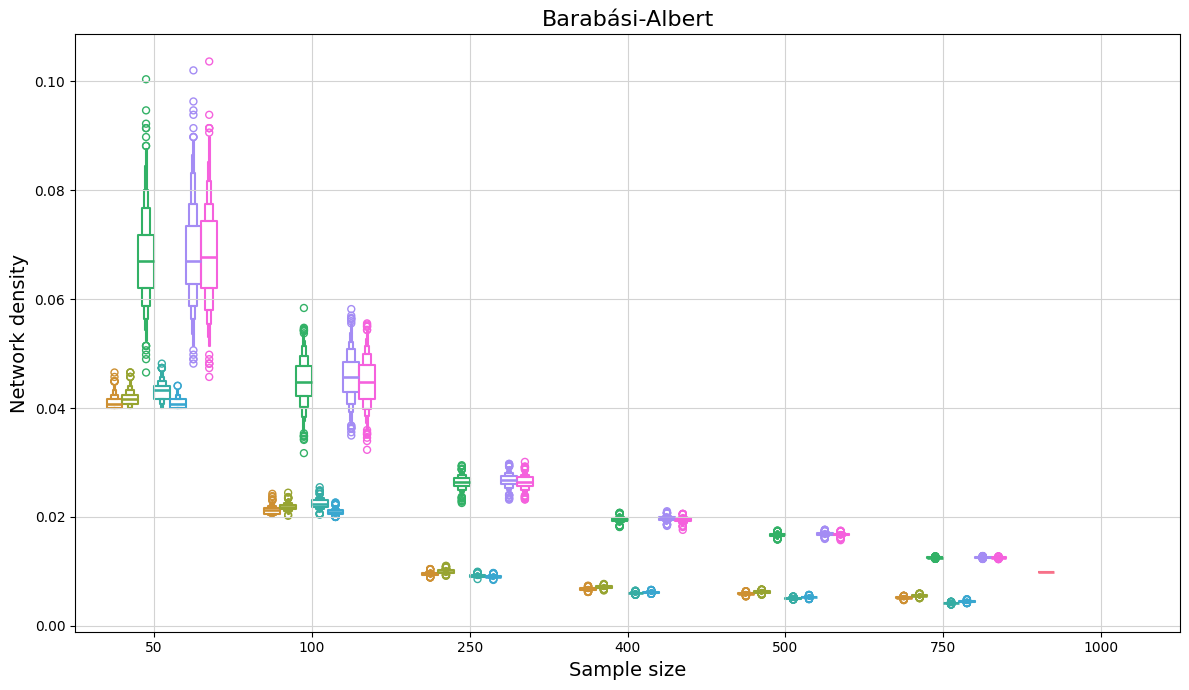

In [87]:
#No legends
df_test = pd.read_csv('data/ba/combined_metrics.csv')
fig, ax = plt.subplots(figsize = (12, 7))
sns.boxenplot(df_test, 
                x='sample_size', 
                y='net_density', 
                hue='sampling_method', 
                hue_order=['Original', 'snowball','RWS','IRWS',
                           'traceroute','MHRW','forest_fire_sampling',
                           'frontier_sampling'],         #same as in the PCA figures
                fill=False, 
                ax=ax, 
                palette='husl')

plt.grid(visible='False', color='lightgrey')

ax.set_ylabel('Network density', fontsize = 14)
ax.set_xlabel('Sample size', fontsize = 14)
plt.title('Barabási-Albert', fontsize = 16)
ax.get_legend().remove()

plt.tight_layout()
plt.savefig('density_ba.pdf', format='pdf')
plt.show()

In [115]:
df = pd.read_csv('data/ba/combined_metrics.csv')

## PCA

In [116]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 57.7%
PCA Component 2 EVR: 18.3%
PCA Component 3 EVR: 9.4%


In [4]:
df_pca = pd.read_csv('data/pca/pca_ba.csv')

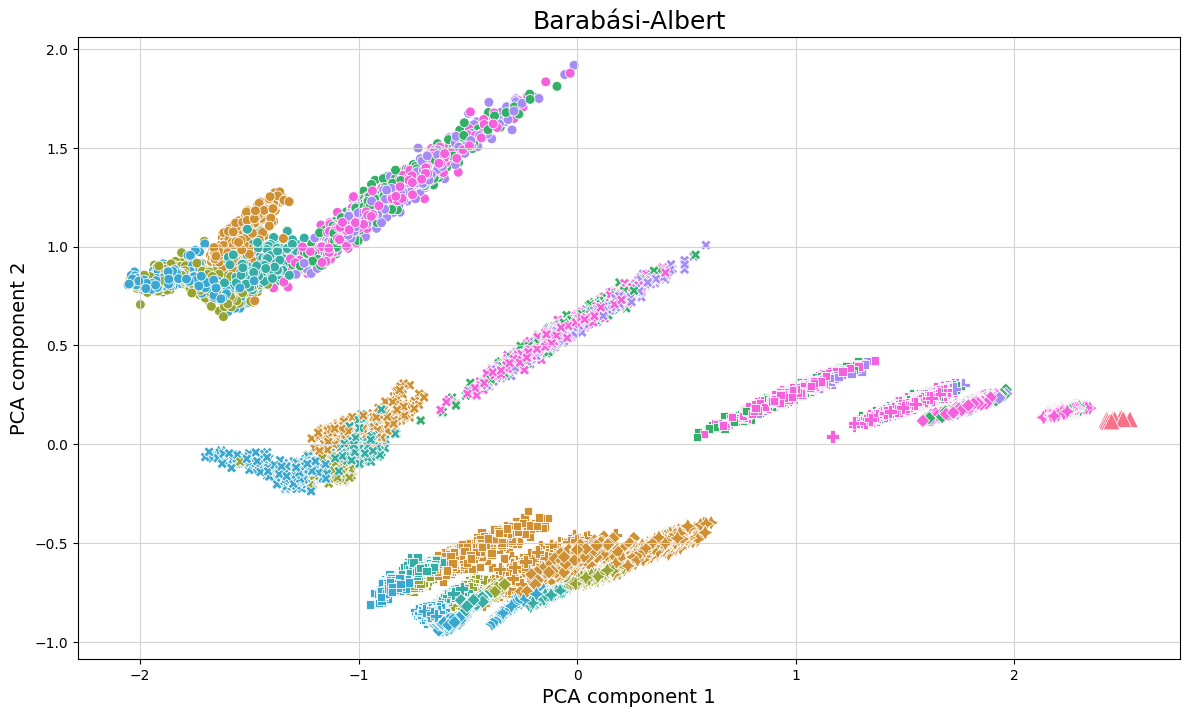

In [74]:
fig, ax = plt.subplots(figsize = (12, 7))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                hue = "sampling_method", 
                palette = "husl",
                size='sample_size',
                sizes=(50,150),
                style='sample_size')
#plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
#            loc="center left", borderaxespad=0.)
ax.get_legend().remove()

plt.grid(visible='False', color='lightgrey')


ax.set_xlabel('PCA component 1', fontsize = 14)
ax.set_ylabel('PCA component 2', fontsize = 14)

plt.tight_layout()
plt.title('Barabási-Albert', fontsize=18)
plt.savefig('PCA_ba.pdf', format='pdf')
plt.show()

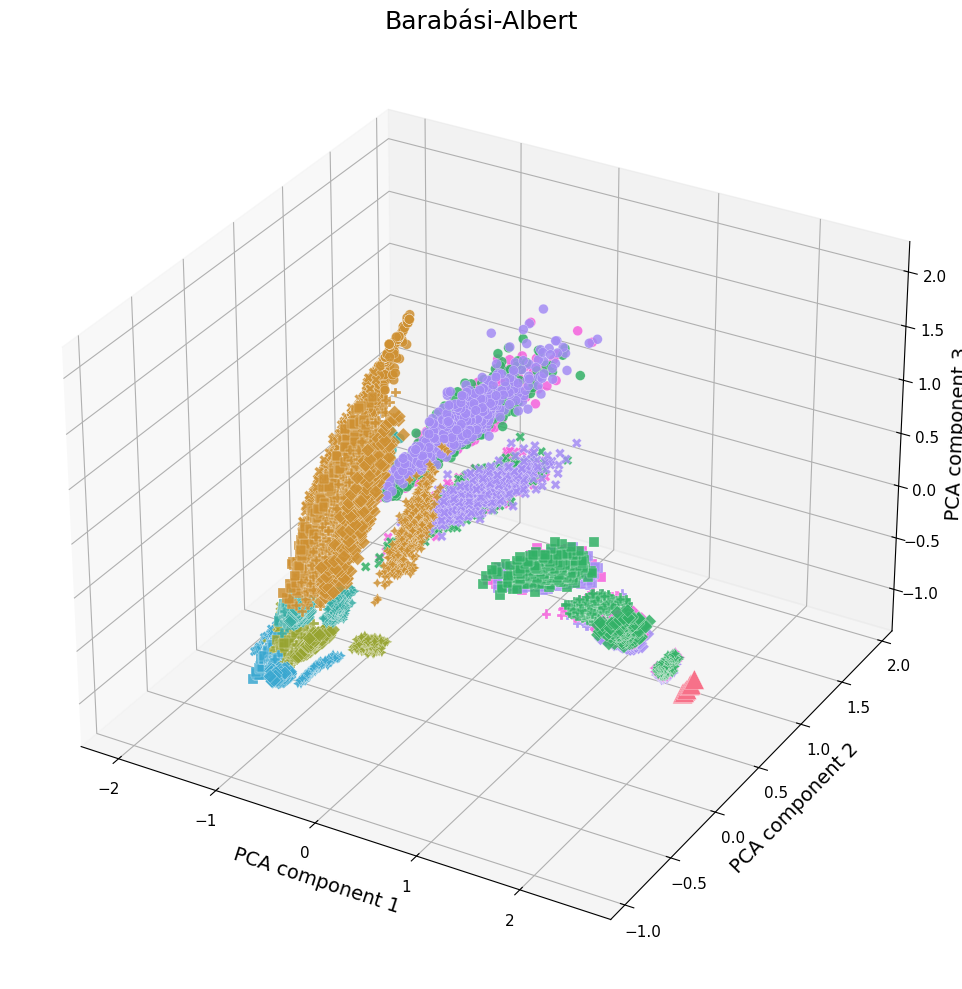

In [7]:
# 1. Extract series
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']

plt.rc('xtick', labelsize=11) 
fig = plt.figure(figsize=(16, 10))
ax = fig.add_subplot(111, projection='3d')

# 2. Extract unique values directly from the dataframe
unique_methods = m.dropna().unique()
unique_sizes = sizes.dropna().unique()

markers_to_use = ['^', 'o', 'X', 's', 'P', 'D', (4,1,0)]

palette = sns.color_palette('husl', len(unique_methods))
color_map = dict(zip(unique_methods, palette))

# Using cycle ensures every unique size gets a marker without raising a KeyError
marker_map = dict(zip(unique_sizes, cycle(markers_to_use)))

# 3. Plot points
for method in unique_methods:
    for size in unique_sizes:
        mask = (df_pca['sampling_method'] == method) & (df_pca['sample_size'] == size)
        if not mask.any():
            continue

        is_original = (method == "Original")
        
        ax.scatter(
            xs[mask], ys[mask], zs[mask], 
            color=color_map[method],
            marker=marker_map[size],
            s=200 if is_original else 50,
            alpha=1.0 if is_original else 0.85,
            edgecolors='w',
            linewidth=0.2
        )

# 4. Format axes and grid
ax.set_xlabel('PCA component 1', fontsize=14)
ax.set_ylabel('PCA component 2', fontsize=14)
ax.set_zlabel('PCA component 3', fontsize=14)
ax.grid(True)

# 5. Legend setup
method_handles = [
    Line2D([0], [0], marker='o', color='w', label=str(method), 
           markerfacecolor=color_map[method], markersize=10)
    for method in unique_methods
]

size_handles = [
    Line2D([0], [0], marker=marker_map[size], color='w', label=f'Size: {size}', 
           markerfacecolor='gray', markersize=10)
    for size in unique_sizes
]

legend_methods = ax.legend(handles=method_handles, title="Sampling Method", 
                           fontsize=11, title_fontsize=12, loc='upper left')
#ax.add_artist(legend_methods)

#ax.legend(handles=size_handles, title="Sample Size", 
#          fontsize=11, title_fontsize=12, loc='upper right')

ax.get_legend().remove()
plt.title('Barabási-Albert', fontsize=18)
plt.tight_layout()
plt.savefig('PCA_ba_3D.pdf', format='pdf', dpi=100, bbox_inches='tight')
plt.show()

In [118]:
df_pca.to_csv('data/pca/pca_ba.csv')

# Non-linear Barabási-Albert networks

## Sampling and metrics computation

In [ ]:
graph_list = []

av_degree = 10  
m = int(av_degree / 2)  
alpha = 1.5
random.seed(42)

for i in range(10):
    seed = random.randint(1, 1000000)
    G = nonlinear_barabasi_albert_graph(1000, m, alpha, seed=seed)
    graph_list.append(G)

In [ ]:
och = st.Samnet_ochestrator(graph_list=graph_list)

och.sample_genesis(sampling_methods_list=[snowball, RWS, IRWS, traceroute, MHRW, forest_fire_sampling,frontier_sampling], 
                    sample_sizes=[50,100,250,400,500,750], runs=50)

Sampling graphs: 100%|██████████| 21000/21000 [00:17<00:00, 1180.63it/s]


In [47]:
func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics) and i.split('_')[0] != ('get') and i.split('_')[0] != ('eigsh'):
        func_list.append(obj)

In [49]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/nlba/')

Metric 14/14 (transitivity): 100%|██████████| 21010/21010 [00:09<00:00, 2266.42it/s]


,graph_id,sampling_method,sample_size,sample_edges,net_density,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,...,pagerank_info_moment_4,pagerank_info_shannon,spectral_distance_info_max,spectral_distance_info_mean,spectral_distance_info_moment_1,spectral_distance_info_moment_2,spectral_distance_info_moment_3,spectral_distance_info_moment_4,spectral_distance_info_shannon,transitivity
0,0,Original,1000,4985,0.009980,-0.346670,2.187405,0.001190,0.000209,0.000058,...,2.060406e-08,0.0,34.322005,3.924832,3.924832,19.940000,177.932089,2764.001760,3.567595,0.023881
1,1,Original,1000,4985,0.009980,-0.307017,2.251381,0.001254,0.000209,0.000055,...,1.676528e-08,0.0,33.808283,3.966167,3.966167,19.940000,168.584840,2480.980848,3.727157,0.025083
2,2,Original,1000,4985,0.009980,-0.349742,2.309766,0.001312,0.000159,0.000030,...,9.026249e-09,0.0,30.838288,3.961286,3.961286,19.940000,163.839526,2210.857680,3.668028,0.026854
3,3,Original,1000,4985,0.009980,-0.339613,2.162288,0.001165,0.000220,0.000058,...,2.544512e-08,0.0,35.014283,3.928612,3.928612,19.940000,180.950202,2945.696424,3.610640,0.023815
4,4,Original,1000,4985,0.009980,-0.288427,2.151810,0.001154,0.000285,0.000102,...,3.244675e-08,0.0,37.161808,3.953937,3.953937,19.940000,177.183495,2900.097408,3.724919,0.021575
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21005,9,frontier_sampling,750,3627,0.012913,-0.375056,2.213024,0.001622,0.000243,0.000055,...,2.518573e-08,0.0,28.827071,3.886652,3.886652,19.344000,156.873282,2055.604053,3.719356,0.031000
21006,9,frontier_sampling,750,3619,0.012885,-0.376558,2.222533,0.001634,0.000238,0.000052,...,2.391479e-08,0.0,28.583212,3.883956,3.883956,19.301333,155.789454,2025.581852,3.746566,0.031241
21007,9,frontier_sampling,750,3636,0.012945,-0.377004,2.211265,0.001619,0.000241,0.000054,...,2.474192e-08,0.0,28.809721,3.890360,3.890360,19.392000,157.376874,2059.245056,3.722742,0.031267
21008,9,frontier_sampling,750,3637,0.012949,-0.366019,2.217688,0.001628,0.000247,0.000058,...,2.478446e-08,0.0,28.879058,3.899343,3.899343,19.397333,156.277431,2034.990393,3.794831,0.031306


In [50]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/nlba/', output_filename='combined_metrics.csv'
)

Successfully combined 14 files into 'data/nlba/combined_metrics.csv' (21010 rows, 53 columns).


## PCA and graphic analysis

In [ ]:
df = pd.read_csv('data/nlba/combined_metrics.csv')

In [120]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 59.4%
PCA Component 2 EVR: 19.7%
PCA Component 3 EVR: 10.0%


In [53]:
df_pca.to_csv('data/pca/pca_nlba.csv')

In [8]:
df_pca = pd.read_csv('data/pca/pca_nlba.csv', index_col=0)

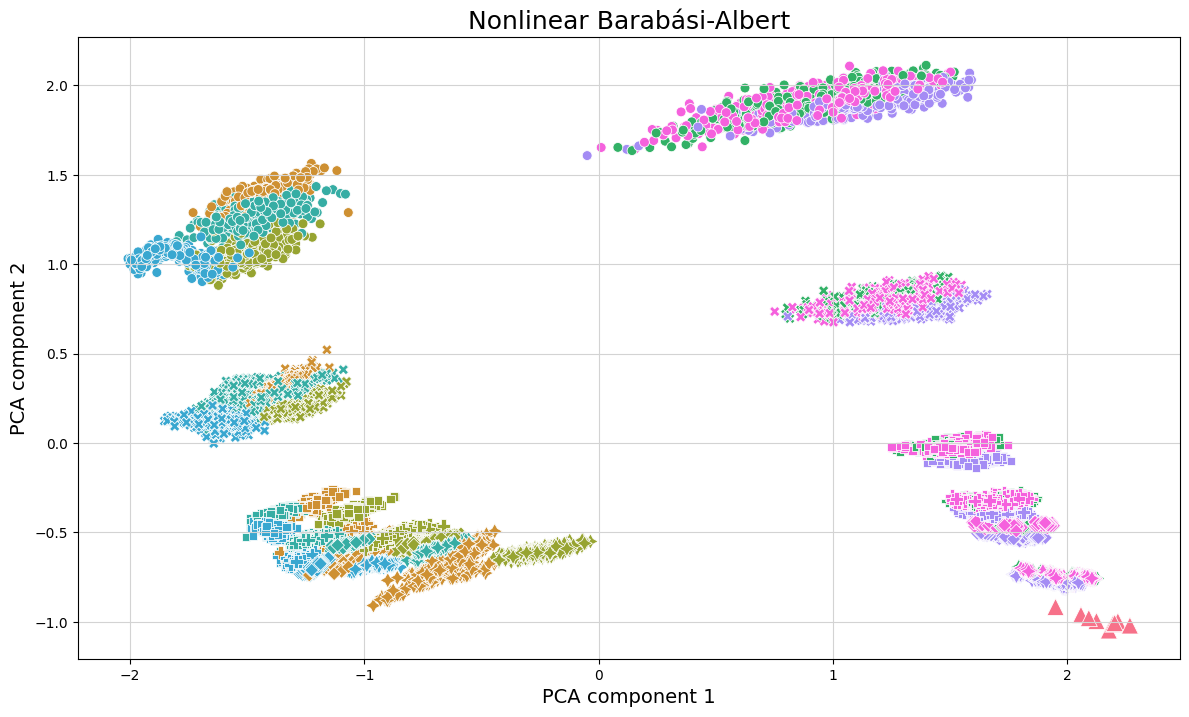

In [76]:
fig, ax = plt.subplots(figsize = (12, 7))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                hue = "sampling_method", 
                palette = "husl",
                size='sample_size',
                sizes=(50,150),
                style='sample_size')
#plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
#            loc="center left", borderaxespad=0.)
ax.get_legend().remove()

plt.grid(visible='False', color='lightgrey')


ax.set_xlabel('PCA component 1', fontsize = 14)
ax.set_ylabel('PCA component 2', fontsize = 14)

plt.tight_layout()
plt.title('Nonlinear Barabási-Albert', fontsize=18)
plt.savefig('PCA_nlba.pdf', format='pdf')
plt.show()

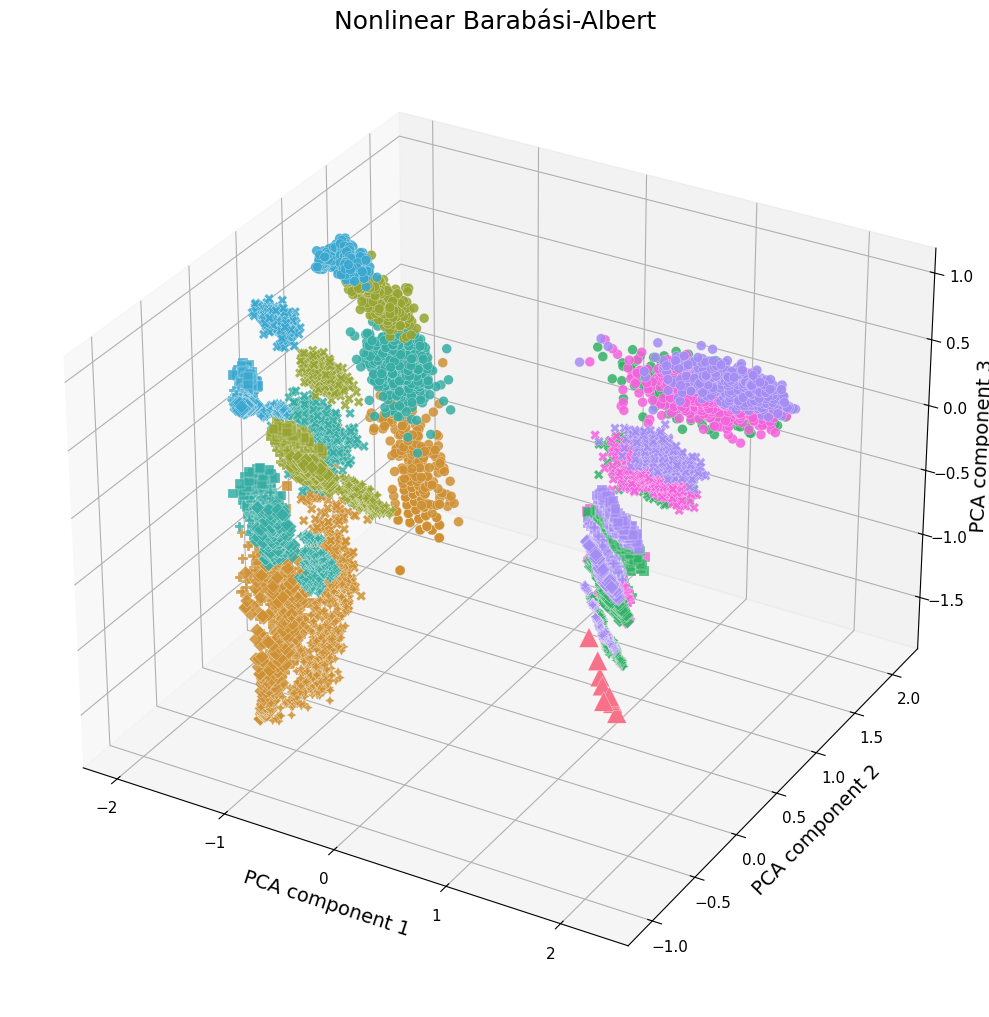

In [9]:
# 1. Extract series
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']

plt.rc('xtick', labelsize=11) 
fig = plt.figure(figsize=(16, 10))
ax = fig.add_subplot(111, projection='3d')

# 2. Extract unique values directly from the dataframe
unique_methods = m.dropna().unique()
unique_sizes = sizes.dropna().unique()

markers_to_use = ['^', 'o', 'X', 's', 'P', 'D', (4,1,0)]

palette = sns.color_palette('husl', len(unique_methods))
color_map = dict(zip(unique_methods, palette))

# Using cycle ensures every unique size gets a marker without raising a KeyError
marker_map = dict(zip(unique_sizes, cycle(markers_to_use)))

# 3. Plot points
for method in unique_methods:
    for size in unique_sizes:
        mask = (df_pca['sampling_method'] == method) & (df_pca['sample_size'] == size)
        if not mask.any():
            continue

        is_original = (method == "Original")
        
        ax.scatter(
            xs[mask], ys[mask], zs[mask], 
            color=color_map[method],
            marker=marker_map[size],
            s=200 if is_original else 50,
            alpha=1.0 if is_original else 0.85,
            edgecolors='w',
            linewidth=0.2
        )

# 4. Format axes and grid
ax.set_xlabel('PCA component 1', fontsize=14)
ax.set_ylabel('PCA component 2', fontsize=14)
ax.set_zlabel('PCA component 3', fontsize=14)
ax.grid(True)

# 5. Legend setup
method_handles = [
    Line2D([0], [0], marker='o', color='w', label=str(method), 
           markerfacecolor=color_map[method], markersize=10)
    for method in unique_methods
]

size_handles = [
    Line2D([0], [0], marker=marker_map[size], color='w', label=f'Size: {size}', 
           markerfacecolor='gray', markersize=10)
    for size in unique_sizes
]

legend_methods = ax.legend(handles=method_handles, title="Sampling Method", 
                           fontsize=11, title_fontsize=12, loc='upper left')
#ax.add_artist(legend_methods)

#ax.legend(handles=size_handles, title="Sample Size", 
#          fontsize=11, title_fontsize=12, loc='upper right')

ax.get_legend().remove()
plt.tight_layout()
plt.title('Nonlinear Barabási-Albert', fontsize=18)
plt.savefig('PCA_nlba_3D.pdf', format='pdf', dpi=100, bbox_inches='tight')
plt.show()

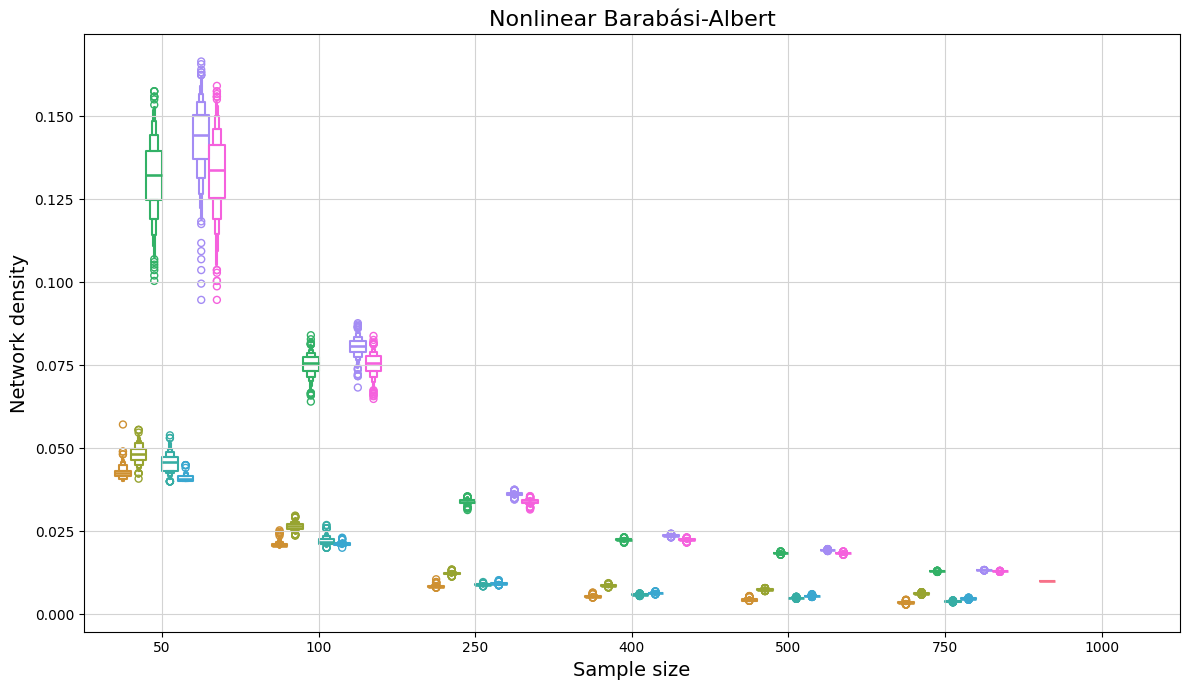

In [88]:
#No legends
df_test = pd.read_csv('data/nlba/combined_metrics.csv')
fig, ax = plt.subplots(figsize = (12, 7))
sns.boxenplot(df_test, 
                x='sample_size', 
                y='net_density', 
                hue='sampling_method', 
                hue_order=['Original', 'snowball','RWS','IRWS',
                           'traceroute','MHRW','forest_fire_sampling',
                           'frontier_sampling'],         #same as in the PCA figures
                fill=False, 
                ax=ax, 
                palette='husl')

plt.grid(visible='False', color='lightgrey')

ax.set_ylabel('Network density', fontsize = 14)
ax.set_xlabel('Sample size', fontsize = 14)
plt.title('Nonlinear Barabási-Albert', fontsize = 16)
ax.get_legend().remove()

plt.tight_layout()
plt.savefig('density_nlba.pdf', format='pdf')
plt.show()

# Erdos-Reyni

## Sampling and metrics computation

In [ ]:
graph_list = []
N=1000
av_degree = 10
p = av_degree / (N - 1)

random.seed(42)
for i in range(10):
    seed = random.randint(1, 1000000)
    G = nx.erdos_renyi_graph(N, p, seed=seed)
    graph_list.append(G)

In [ ]:
och = st.Samnet_ochestrator(graph_list=graph_list)

och.sample_genesis(sampling_methods_list=[snowball, RWS, IRWS, traceroute, MHRW, forest_fire_sampling,frontier_sampling], 
                    sample_sizes=[50,100,250,400,500,750], runs=50)

Sampling graphs: 100%|██████████| 21000/21000 [00:21<00:00, 964.25it/s]


In [61]:
func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics) and i.split('_')[0] != ('get') and i.split('_')[0] != ('eigsh'):
        func_list.append(obj)

In [62]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/er/')

Metric 14/14 (transitivity): 100%|██████████| 21010/21010 [00:05<00:00, 3795.37it/s]


,graph_id,sampling_method,sample_size,sample_edges,net_density,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,...,pagerank_info_moment_4,pagerank_info_shannon,spectral_distance_info_max,spectral_distance_info_mean,spectral_distance_info_moment_1,spectral_distance_info_moment_2,spectral_distance_info_moment_3,spectral_distance_info_moment_4,spectral_distance_info_shannon,transitivity
0,0,Original,1000,4961,0.009932,0.005923,3.264026,0.002269,0.000007,2.958878e-08,...,1.480961e-12,0.0,6.633250,4.423222,4.423222,19.844000,90.149435,414.478080,4.216152,0.010585
1,1,Original,1000,4947,0.009904,0.008238,3.266995,0.002272,0.000007,2.821930e-08,...,1.472196e-12,0.0,6.324555,4.416276,4.416276,19.788000,89.795078,412.382304,4.226444,0.009657
2,2,Original,1000,4880,0.009770,0.003843,3.286160,0.002291,0.000007,2.991234e-08,...,1.481564e-12,0.0,6.324555,4.386552,4.386552,19.520000,87.971667,401.282856,4.202668,0.010001
3,3,Original,1000,4982,0.009974,0.000765,3.264102,0.002269,0.000007,2.663486e-08,...,1.431145e-12,0.0,6.557439,4.434547,4.434547,19.928000,90.599262,416.465304,4.171767,0.009661
4,4,Original,1000,5065,0.010140,-0.005581,3.240659,0.002245,0.000007,2.565899e-08,...,1.416909e-12,0.0,6.403124,4.472552,4.472552,20.260000,92.805441,429.670216,4.165170,0.010781
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21005,9,frontier_sampling,750,3177,0.011311,0.029190,3.339781,0.003128,0.000014,7.797219e-08,...,4.689949e-12,0.0,6.164414,4.085411,4.085411,16.944000,71.194214,302.855652,4.020986,0.010036
21006,9,frontier_sampling,750,3088,0.010994,0.004327,3.372005,0.003171,0.000015,9.010711e-08,...,4.889232e-12,0.0,6.244998,4.025836,4.025836,16.469333,68.323234,287.250546,4.028242,0.009383
21007,9,frontier_sampling,750,3111,0.011076,-0.002215,3.364098,0.003161,0.000014,8.629348e-08,...,4.842623e-12,0.0,6.164414,4.042007,4.042007,16.592000,69.037858,291.032633,4.010927,0.010444
21008,9,frontier_sampling,750,3150,0.011215,0.036753,3.352160,0.003145,0.000014,7.989390e-08,...,4.678322e-12,0.0,5.916080,4.068503,4.068503,16.800000,70.268366,297.527324,3.997299,0.010464


In [63]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/er/', output_filename='combined_metrics.csv'
)

Successfully combined 14 files into 'data/er/combined_metrics.csv' (21010 rows, 53 columns).


## PCA and graphic analysis

In [ ]:
df = pd.read_csv('data/er/combined_metrics.csv')

In [124]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 54.7%
PCA Component 2 EVR: 21.6%
PCA Component 3 EVR: 7.9%


In [125]:
df_pca.to_csv('data/pca/pca_er.csv')

In [10]:
df_pca = pd.read_csv('data/pca/pca_er.csv')

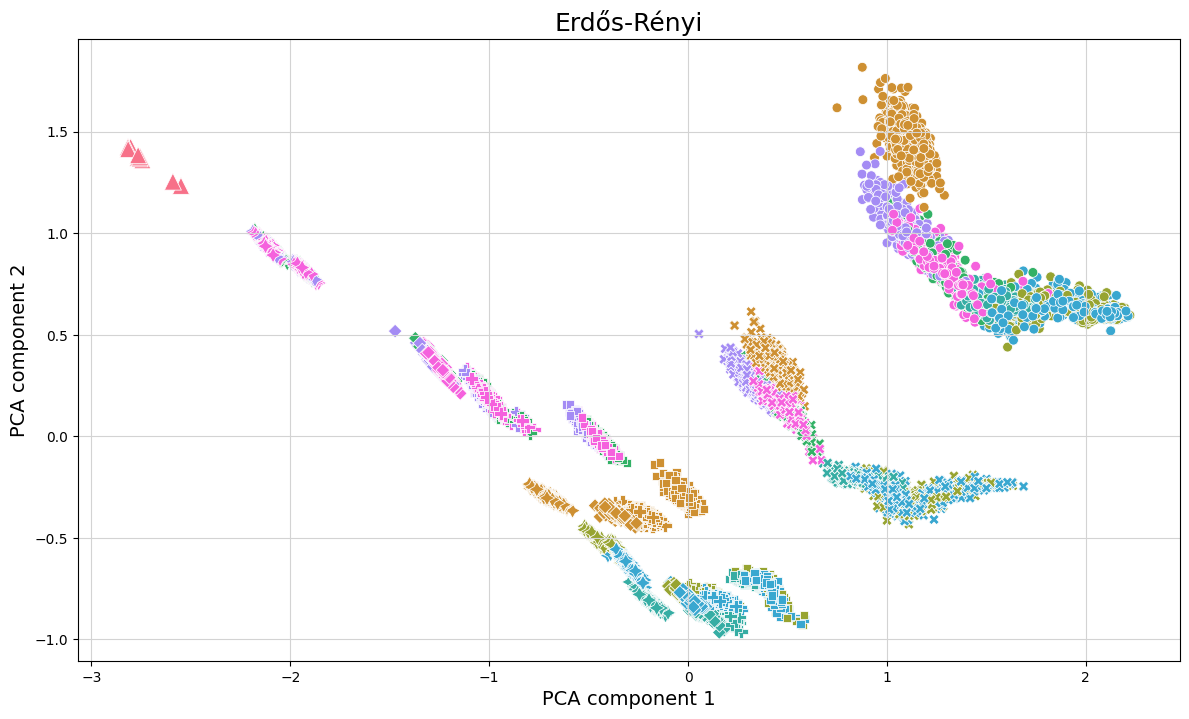

In [ ]:
fig, ax = plt.subplots(figsize = (12, 7))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                hue = "sampling_method", 
                palette = "husl",
                size='sample_size',
                sizes=(50,150),
                style='sample_size')
#plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
#            loc="center left", borderaxespad=0.)
ax.get_legend().remove()

plt.grid(visible='False', color='lightgrey')


ax.set_xlabel('PCA component 1', fontsize = 14)
ax.set_ylabel('PCA component 2', fontsize = 14)

plt.tight_layout()
plt.title('Erdős-Rényi', fontsize=18)
plt.savefig('PCA_er.pdf', format='pdf')
plt.show()

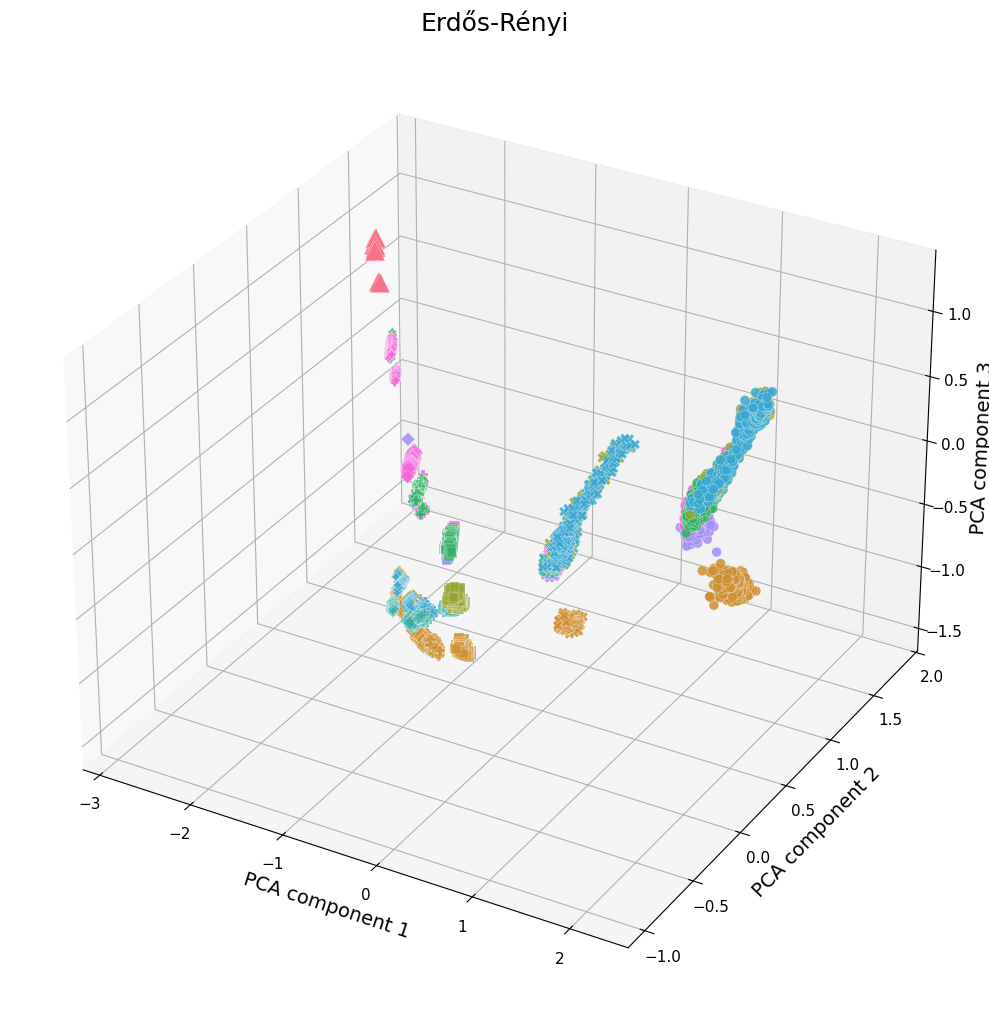

In [11]:
# 1. Extract series
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']

plt.rc('xtick', labelsize=11) 
fig = plt.figure(figsize=(16, 10))
ax = fig.add_subplot(111, projection='3d')

# 2. Extract unique values directly from the dataframe
unique_methods = m.dropna().unique()
unique_sizes = sizes.dropna().unique()

markers_to_use = ['^', 'o', 'X', 's', 'P', 'D', (4,1,0)]

palette = sns.color_palette('husl', len(unique_methods))
color_map = dict(zip(unique_methods, palette))

# Using cycle ensures every unique size gets a marker without raising a KeyError
marker_map = dict(zip(unique_sizes, cycle(markers_to_use)))

# 3. Plot points
for method in unique_methods:
    for size in unique_sizes:
        mask = (df_pca['sampling_method'] == method) & (df_pca['sample_size'] == size)
        if not mask.any():
            continue

        is_original = (method == "Original")
        
        ax.scatter(
            xs[mask], ys[mask], zs[mask], 
            color=color_map[method],
            marker=marker_map[size],
            s=200 if is_original else 50,
            alpha=1.0 if is_original else 0.85,
            edgecolors='w',
            linewidth=0.2
        )

# 4. Format axes and grid
ax.set_xlabel('PCA component 1', fontsize=14)
ax.set_ylabel('PCA component 2', fontsize=14)
ax.set_zlabel('PCA component 3', fontsize=14)
ax.grid(True)

# 5. Legend setup
method_handles = [
    Line2D([0], [0], marker='o', color='w', label=str(method), 
           markerfacecolor=color_map[method], markersize=10)
    for method in unique_methods
]

size_handles = [
    Line2D([0], [0], marker=marker_map[size], color='w', label=f'Size: {size}', 
           markerfacecolor='gray', markersize=10)
    for size in unique_sizes
]

legend_methods = ax.legend(handles=method_handles, title="Sampling Method", 
                           fontsize=11, title_fontsize=12, loc='upper left')
#ax.add_artist(legend_methods)

#ax.legend(handles=size_handles, title="Sample Size", 
#          fontsize=11, title_fontsize=12, loc='upper right')

ax.get_legend().remove()
plt.tight_layout()
plt.title('Erdős-Rényi', fontsize=18)
plt.savefig('PCA_er_3D.pdf', format='pdf', dpi=100, bbox_inches='tight')
plt.show()

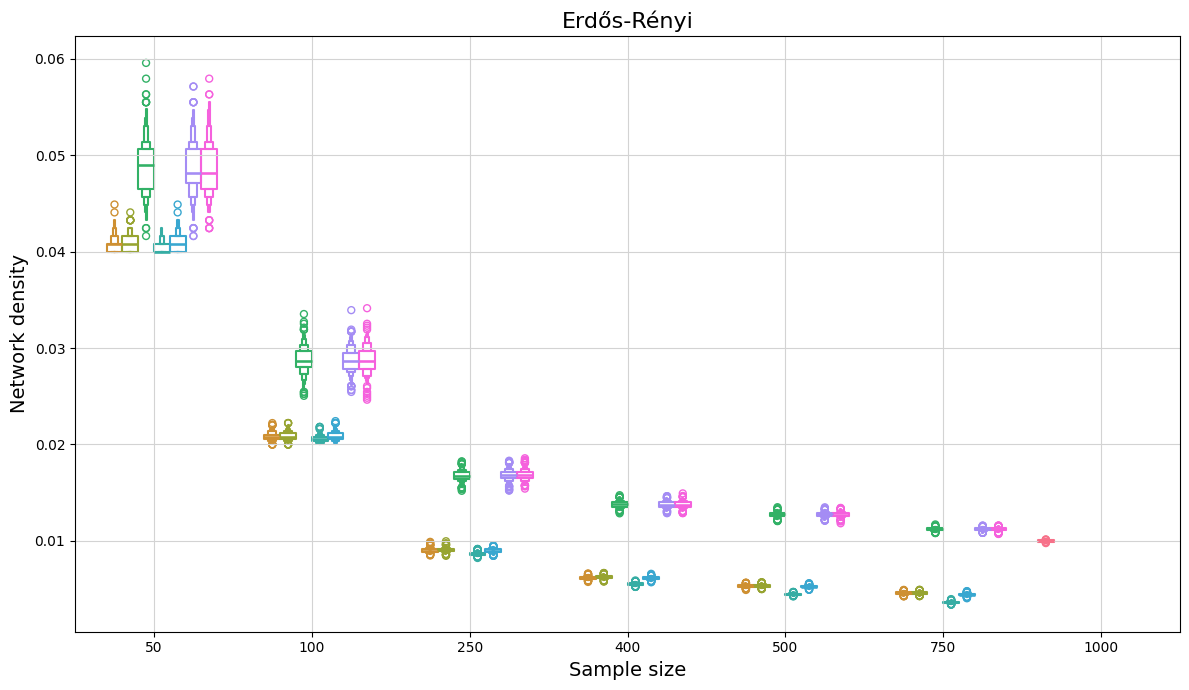

In [89]:
#No legends
df_test = pd.read_csv('data/er/combined_metrics.csv')
fig, ax = plt.subplots(figsize = (12, 7))
sns.boxenplot(df_test, 
                x='sample_size', 
                y='net_density', 
                hue='sampling_method', 
                hue_order=['Original', 'snowball','RWS','IRWS',
                           'traceroute','MHRW','forest_fire_sampling',
                           'frontier_sampling'],         #same as in the PCA figures
                fill=False, 
                ax=ax, 
                palette='husl')

plt.grid(visible='False', color='lightgrey')

ax.set_ylabel('Network density', fontsize = 14)
ax.set_xlabel('Sample size', fontsize = 14)
plt.title('Erdős-Rényi', fontsize = 16)
ax.get_legend().remove()

plt.tight_layout()
plt.savefig('density_er.pdf', format='pdf')
plt.show()

# Watts-Strogatz (p=0.01)

## Sampling and metrics computation

In [ ]:
graph_list = []
av_degree = 10 
p = 0.01
k = int(av_degree / 2)

random.seed(42)
for i in range(10):
    seed = random.randint(1, 1000000)
    G = nx.watts_strogatz_graph(1000, k, p, seed=seed)
    graph_list.append(G)

In [ ]:
och = st.Samnet_ochestrator(graph_list=graph_list)

och.sample_genesis(sampling_methods_list=[snowball, RWS, IRWS, traceroute, MHRW, forest_fire_sampling,frontier_sampling], 
                    sample_sizes=[50,100,250,400,500,750], runs=50)

Sampling graphs: 100%|██████████| 21000/21000 [00:22<00:00, 921.61it/s]


In [73]:
func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics) and i.split('_')[0] != ('get') and i.split('_')[0] != ('eigsh'):
        func_list.append(obj)

In [74]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/ws/')

Metric 14/14 (transitivity): 100%|██████████| 21010/21010 [00:04<00:00, 4847.08it/s]


,graph_id,sampling_method,sample_size,sample_edges,net_density,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,...,pagerank_info_moment_4,pagerank_info_shannon,spectral_distance_info_max,spectral_distance_info_mean,spectral_distance_info_moment_1,spectral_distance_info_moment_2,spectral_distance_info_moment_3,spectral_distance_info_moment_4,spectral_distance_info_shannon,transitivity
0,0,Original,1000,2000,0.004004,0.042082,30.060951,0.029119,0.001858,0.000217,...,1.008027e-12,0.0,3.464102,2.826556,2.826556,8.000000,22.649808,64.148136,0.468984,0.485624
1,1,Original,1000,2000,0.004004,-0.030095,31.107704,0.030168,0.001862,0.000192,...,1.008839e-12,0.0,3.316625,2.826534,2.826534,8.000000,22.650340,64.152144,0.487402,0.483549
2,2,Original,1000,2000,0.004004,-0.013348,25.437213,0.024486,0.001647,0.000236,...,1.011320e-12,0.0,3.464102,2.826427,2.826427,8.000000,22.652968,64.172184,0.555271,0.483646
3,3,Original,1000,2000,0.004004,0.022556,28.973175,0.028029,0.001732,0.000173,...,1.009566e-12,0.0,3.464102,2.826490,2.826490,8.000000,22.651404,64.160160,0.523146,0.483389
4,4,Original,1000,2000,0.004004,-0.001753,34.026519,0.033093,0.003020,0.000520,...,1.007021e-12,0.0,3.316625,2.826623,2.826623,8.000000,22.648214,64.136112,0.411435,0.488360
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21005,9,frontier_sampling,750,1460,0.005198,0.296518,29.100472,0.037567,0.003007,0.000376,...,3.274981e-12,0.0,3.464102,2.786096,2.786096,7.786667,21.798442,61.117383,1.151058,0.486034
21006,9,frontier_sampling,750,1475,0.005251,0.266173,32.307681,0.041855,0.004028,0.000633,...,3.236797e-12,0.0,3.464102,2.801298,2.801298,7.866667,22.114713,62.230357,0.895203,0.490622
21007,9,frontier_sampling,750,1472,0.005241,0.254634,27.122684,0.034923,0.002902,0.000425,...,3.246505e-12,0.0,3.316625,2.798118,2.798118,7.850667,22.054488,62.029710,1.012891,0.485668
21008,9,frontier_sampling,750,1470,0.005234,0.247453,26.146421,0.033618,0.002806,0.000356,...,3.269369e-12,0.0,3.464102,2.795865,2.795865,7.840000,22.016963,61.913913,1.066398,0.484737


In [75]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/ws/', output_filename='combined_metrics.csv'
)

Successfully combined 14 files into 'data/ws/combined_metrics.csv' (21010 rows, 53 columns).


## PCA and graphic analysis

In [ ]:
df = pd.read_csv('data/ws/combined_metrics.csv')

In [113]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 51.2%
PCA Component 2 EVR: 34.4%
PCA Component 3 EVR: 4.2%


In [78]:
df_pca.to_csv('data/pca/pca_ws.csv')

In [12]:
df_pca = pd.read_csv('data/pca/pca_ws.csv')

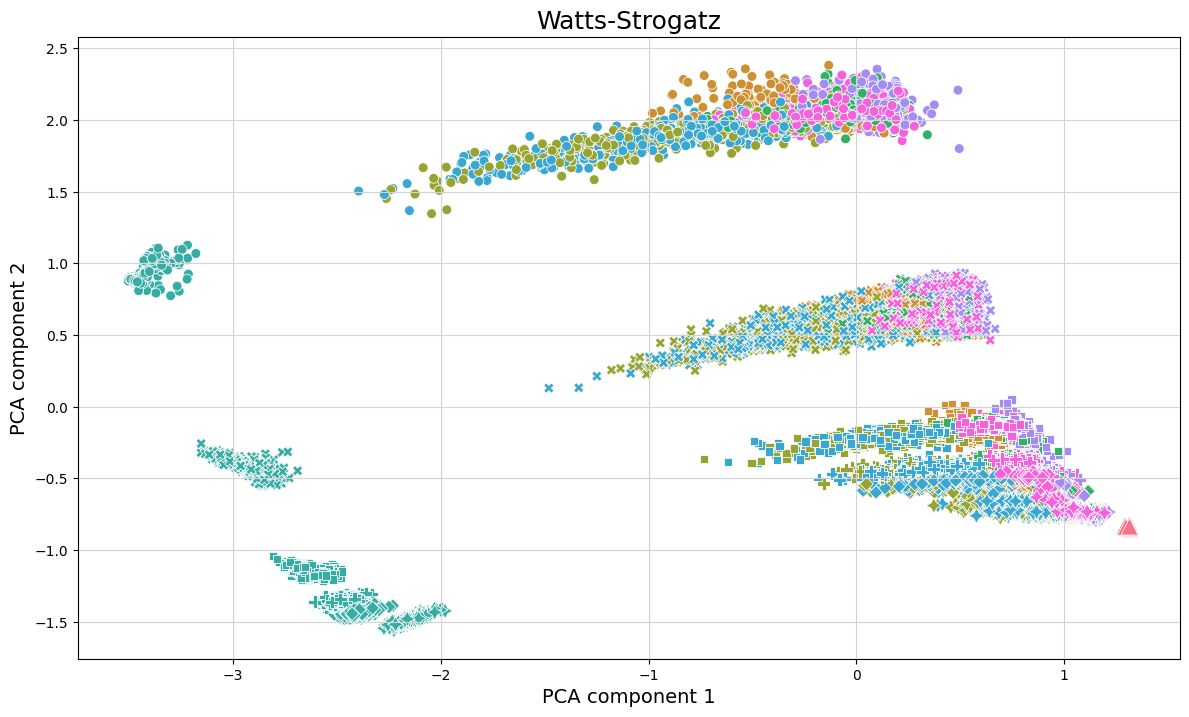

In [79]:
fig, ax = plt.subplots(figsize = (12, 7))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                hue = "sampling_method", 
                palette = "husl",
                size='sample_size',
                sizes=(50,150),
                style='sample_size')
#plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
#            loc="center left", borderaxespad=0.)
ax.get_legend().remove()

plt.grid(visible='False', color='lightgrey')


ax.set_xlabel('PCA component 1', fontsize = 14)
ax.set_ylabel('PCA component 2', fontsize = 14)

plt.tight_layout()
plt.title('Watts-Strogatz', fontsize=18)
plt.savefig('PCA_ws.pdf', format='pdf')
plt.show()

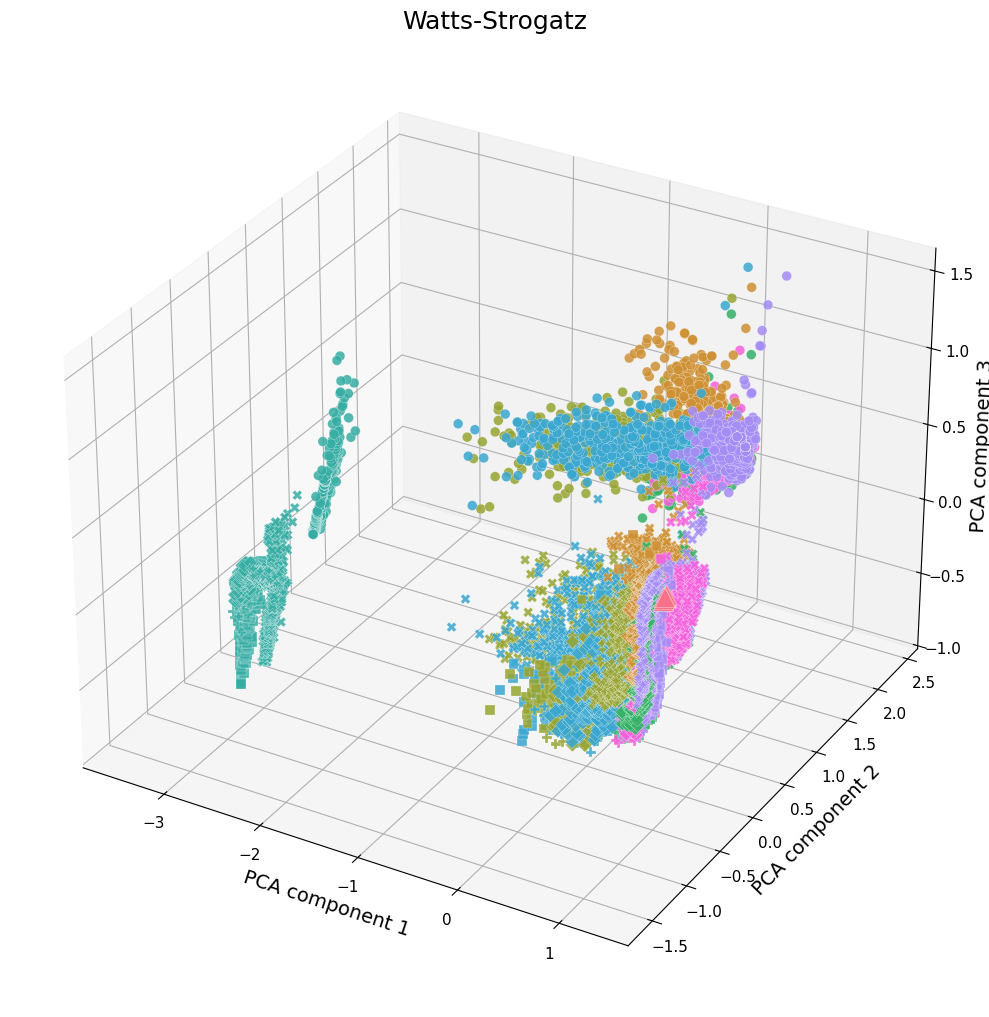

In [ ]:
# 1. Extract series
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']

plt.rc('xtick', labelsize=11) 
fig = plt.figure(figsize=(16, 10))
ax = fig.add_subplot(111, projection='3d')

# 2. Extract unique values directly from the dataframe
unique_methods = m.dropna().unique()
unique_sizes = sizes.dropna().unique()

markers_to_use = ['^', 'o', 'X', 's', 'P', 'D', (4,1,0)]

palette = sns.color_palette('husl', len(unique_methods))
color_map = dict(zip(unique_methods, palette))

# Using cycle ensures every unique size gets a marker without raising a KeyError
marker_map = dict(zip(unique_sizes, cycle(markers_to_use)))

# 3. Plot points
for method in unique_methods:
    for size in unique_sizes:
        mask = (df_pca['sampling_method'] == method) & (df_pca['sample_size'] == size)
        if not mask.any():
            continue

        is_original = (method == "Original")
        
        ax.scatter(
            xs[mask], ys[mask], zs[mask], 
            color=color_map[method],
            marker=marker_map[size],
            s=200 if is_original else 50,
            alpha=1.0 if is_original else 0.85,
            edgecolors='w',
            linewidth=0.2
        )

# 4. Format axes and grid
ax.set_xlabel('PCA component 1', fontsize=14)
ax.set_ylabel('PCA component 2', fontsize=14)
ax.set_zlabel('PCA component 3', fontsize=14)
ax.grid(True)

# 5. Legend setup
method_handles = [
    Line2D([0], [0], marker='o', color='w', label=str(method), 
           markerfacecolor=color_map[method], markersize=10)
    for method in unique_methods
]

size_handles = [
    Line2D([0], [0], marker=marker_map[size], color='w', label=f'Size: {size}', 
           markerfacecolor='gray', markersize=10)
    for size in unique_sizes
]

legend_methods = ax.legend(handles=method_handles, title="Sampling Method", 
                           fontsize=11, title_fontsize=12, loc='upper left')

ax.get_legend().remove()
plt.tight_layout()
plt.title('Watts-Strogatz', fontsize=18)
plt.savefig('PCA_ws_3D.pdf', format='pdf', dpi=100, bbox_inches='tight')
plt.show()

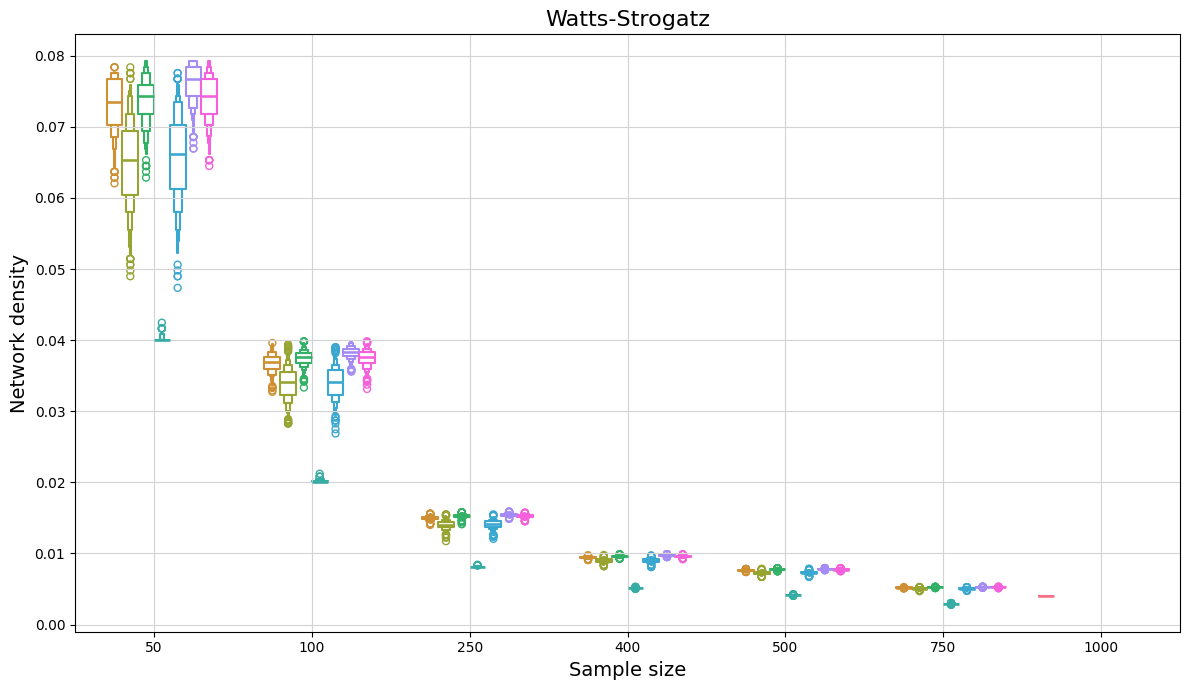

In [90]:
#No legends
df_test = pd.read_csv('data/ws/combined_metrics.csv')
fig, ax = plt.subplots(figsize = (12, 7))
sns.boxenplot(df_test, 
                x='sample_size', 
                y='net_density', 
                hue='sampling_method', 
                hue_order=['Original', 'snowball','RWS','IRWS',
                           'traceroute','MHRW','forest_fire_sampling',
                           'frontier_sampling'],         #same as in the PCA figures
                fill=False, 
                ax=ax, 
                palette='husl')

plt.grid(visible='False', color='lightgrey')

ax.set_ylabel('Network density', fontsize = 14)
ax.set_xlabel('Sample size', fontsize = 14)
plt.title('Watts-Strogatz', fontsize = 16)
ax.get_legend().remove()

plt.tight_layout()
plt.savefig('density_ws.pdf', format='pdf')
plt.show()

# Dispersion distances

In [7]:
#BA
df_pca = pd.read_csv('data/pca/pca_ba.csv', index_col=0)
swp1 = calculate_dispersion_distance(df_pca)

#NLBA
df_pca = pd.read_csv('data/pca/pca_nlba.csv', index_col=0)
swp2 = calculate_dispersion_distance(df_pca)

#ER
df_pca = pd.read_csv('data/pca/pca_er.csv', index_col=0)
swp3 = calculate_dispersion_distance(df_pca)

#WS
df_pca = pd.read_csv('data/pca/pca_ws.csv', index_col=0)
swp4 = calculate_dispersion_distance(df_pca)

In [73]:
#Group and concatenate all the data above 

res = pd.concat([
    #BA - this is the only one that keeps the 'method' and 'sample_size' columns
    swp1.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns='graph_ID').sort_values(by=['sample_size']).rename(columns={
                                                                                    'method': 'method', 'sample_size':'sample_size', 'mean':'mean_BA', 'var': 'var_BA'}),
    #NLBA                                                                                
    swp2.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns=['graph_ID', 'method']).sort_values(by=['sample_size']).drop(columns=['sample_size']).rename(columns={
                                                                                    'method': 'method', 'sample_size':'sample_size', 'mean':'mean_NLBA', 'var': 'var_NLBA'}),
    #ER                                                                                  
    swp3.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns=['graph_ID', 'method']).sort_values(by=['sample_size']).drop(columns=['sample_size']).rename(columns={
                                                                                    'method': 'method', 'sample_size':'sample_size', 'mean':'mean_ER', 'var': 'var_ER'}),
    #WS     
    swp4.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns=['graph_ID', 'method']).sort_values(by=['sample_size']).drop(columns=['sample_size']).rename(columns={
                                                                                    'method': 'method', 'sample_size':'sample_size', 'mean':'mean_WS', 'var': 'var_WS'})      
], axis=1)
res.to_csv('PCA_distances.csv')
res

,method,sample_size,mean_BA,var_BA,mean_NLBA,var_NLBA,mean_ER,var_ER,mean_WS,var_WS
0,IRWS,50,3.926473,0.003882,3.842673,0.002964,4.089552,0.016506,3.506119,0.014366
6,MHRW,50,4.541569,0.020453,4.628595,0.010941,4.745190,0.039076,3.700652,0.041825
12,RWS,50,4.435474,0.022340,4.369476,0.003423,4.731076,0.039583,3.721879,0.038816
18,forest_fire_sampling,50,3.902851,0.003691,3.779295,0.002535,3.876736,0.008493,3.441057,0.021743
24,frontier_sampling,50,3.923854,0.004648,3.838448,0.002927,4.095324,0.015999,3.490905,0.015209
30,snowball,50,4.371237,0.002937,4.600945,0.003076,3.931209,0.003589,3.506896,0.042259
36,traceroute,50,4.242401,0.004092,4.530698,0.005549,4.416801,0.009010,5.065196,0.001320
13,RWS,100,3.677154,0.005148,3.650152,0.002204,4.315669,0.021292,2.106909,0.052842
19,forest_fire_sampling,100,2.745856,0.009962,2.183518,0.001528,3.342882,0.006596,1.794455,0.016719
1,IRWS,100,2.785729,0.011769,2.292907,0.001792,3.498690,0.008396,1.810941,0.012410


Text(0.5, 1.0, 'Watts-Strogatz')

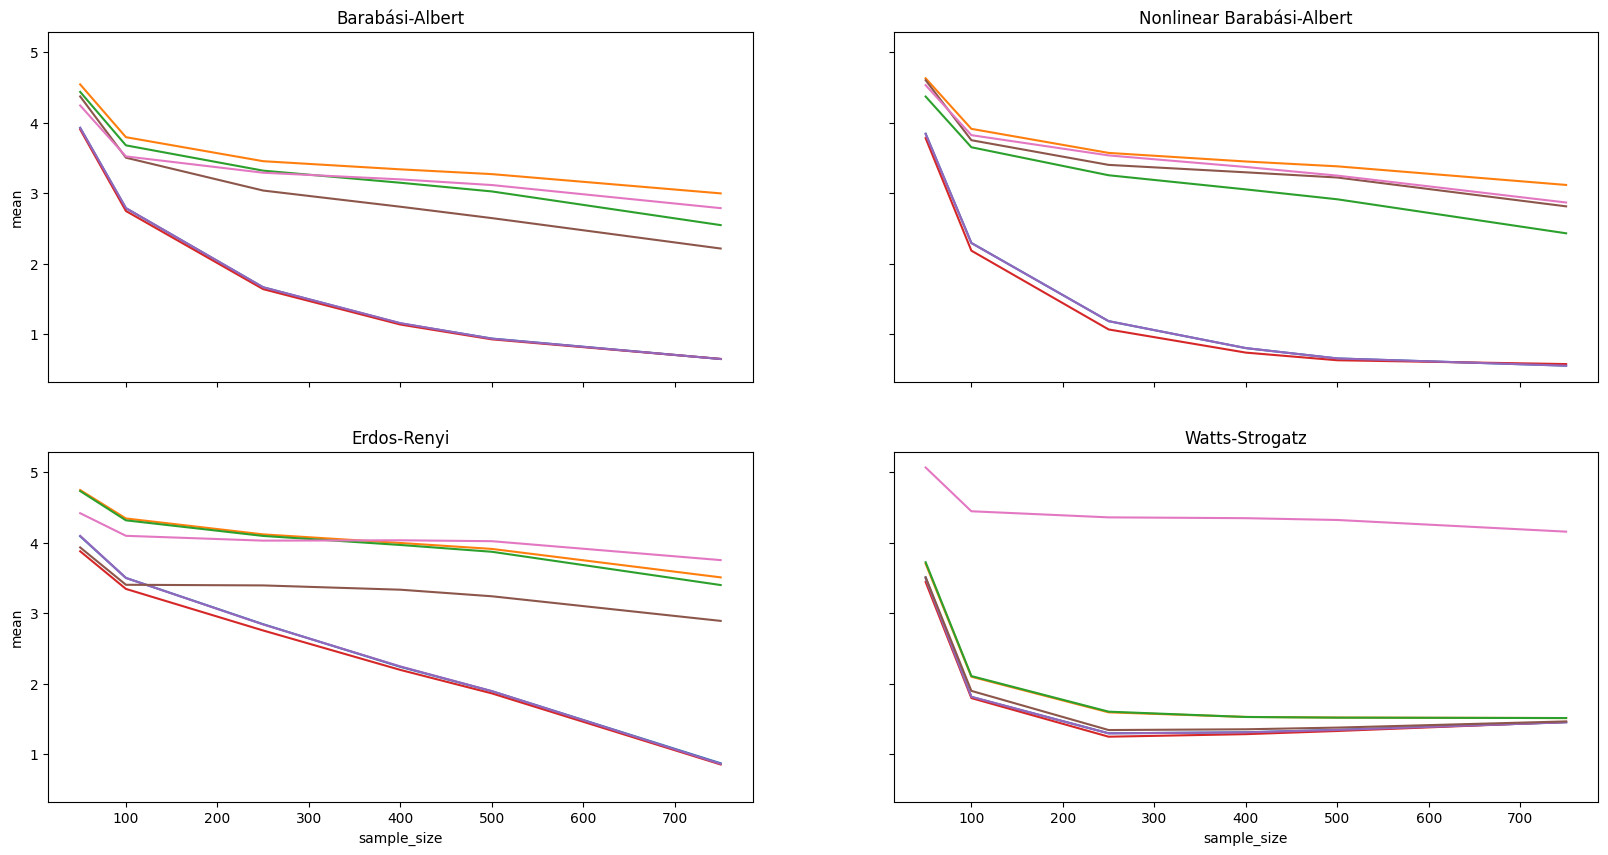

In [65]:
#Mean distances

fig, axes = plt.subplots(2,2, figsize=(20, 10), sharex=True, sharey=True)

#BA
sns.lineplot(swp1.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns='graph_ID').sort_values(by=['sample_size']), 
            x='sample_size',y='mean', hue='method', ax=axes[0][0], legend=False)
axes[0][0].set_title('Barabási-Albert')
#NLBA
sns.lineplot(swp2.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns='graph_ID').sort_values(by=['sample_size']), 
            x='sample_size',y='mean', hue='method', ax=axes[0][1], legend=False)
axes[0][1].set_title('Nonlinear Barabási-Albert')
#ER
sns.lineplot(swp3.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns='graph_ID').sort_values(by=['sample_size']), 
            x='sample_size',y='mean', hue='method', ax=axes[1][0], legend=False)
axes[1][0].set_title('Erdos-Renyi')
#SW
sns.lineplot(swp4.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns='graph_ID').sort_values(by=['sample_size']), 
            x='sample_size',y='mean', hue='method', ax=axes[1][1], legend=False)
axes[1][1].set_title('Watts-Strogatz')

Text(0.5, 1.0, 'Watts-Strogatz')

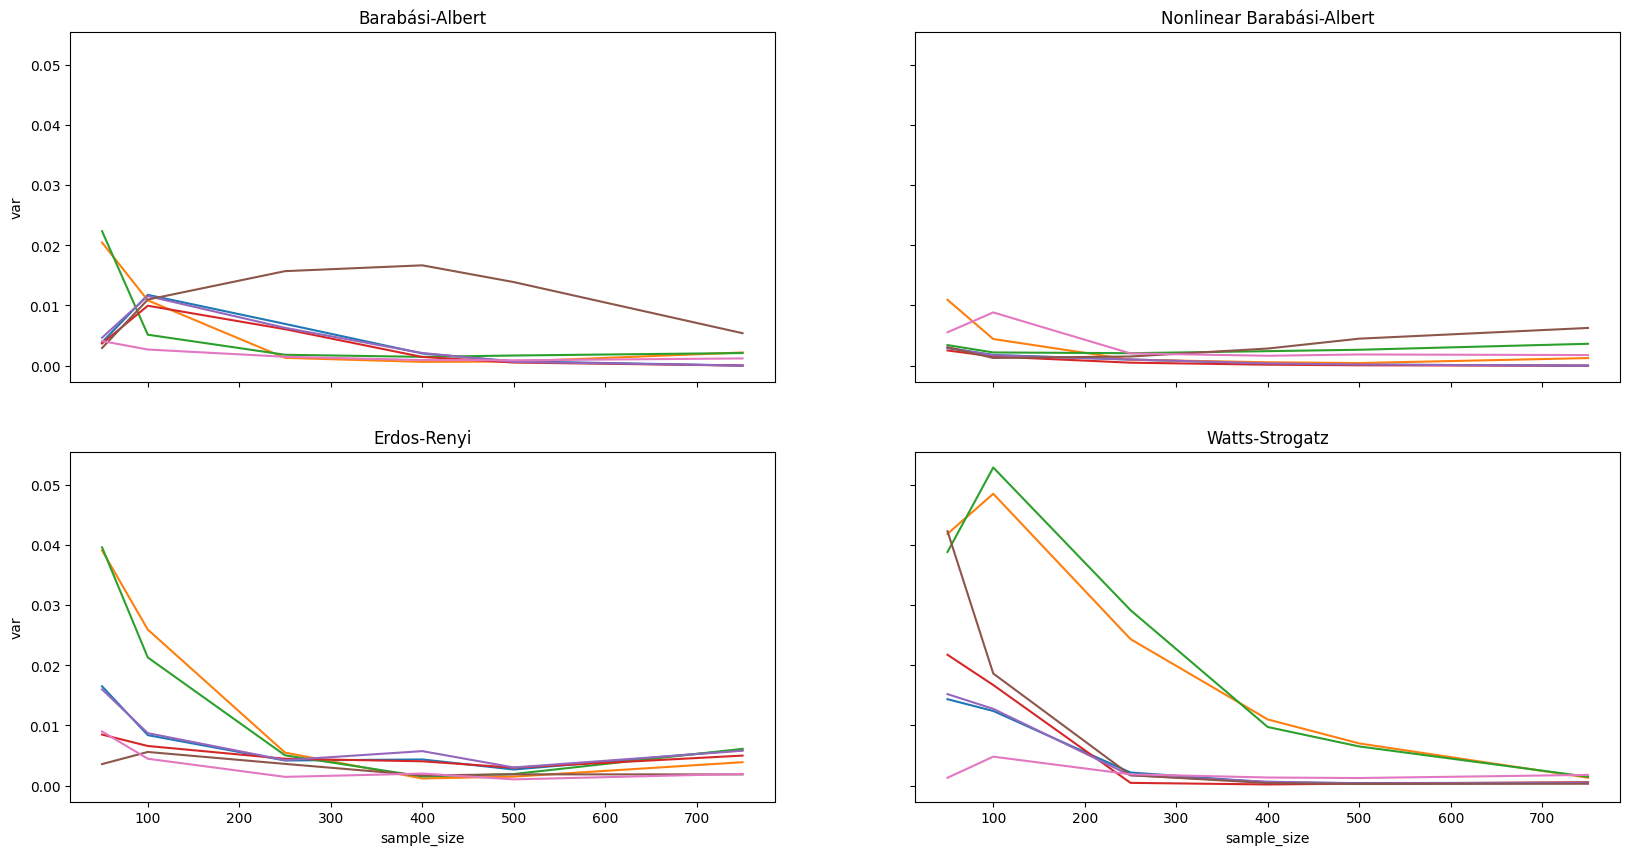

In [77]:
#Var distances

fig, axes = plt.subplots(2,2, figsize=(20, 10), sharex=True, sharey=True)

#BA
sns.lineplot(swp1.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns='graph_ID').sort_values(by=['sample_size']), 
            x='sample_size',y='var', hue='method', ax=axes[0][0], legend=False)
axes[0][0].set_title('Barabási-Albert')
#NLBA
sns.lineplot(swp2.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns='graph_ID').sort_values(by=['sample_size']), 
            x='sample_size',y='var', hue='method', ax=axes[0][1], legend=False)
axes[0][1].set_title('Nonlinear Barabási-Albert')
#ER
sns.lineplot(swp3.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns='graph_ID').sort_values(by=['sample_size']), 
            x='sample_size',y='var', hue='method', ax=axes[1][0], legend=False)
axes[1][0].set_title('Erdos-Renyi')
#SW
sns.lineplot(swp4.groupby(['method', 'sample_size']).agg('mean').reset_index().drop(columns='graph_ID').sort_values(by=['sample_size']), 
            x='sample_size',y='var', hue='method', ax=axes[1][1], legend=False)
axes[1][1].set_title('Watts-Strogatz')

# Test: Frontier parameters

## m=1

In [ ]:
graph_list = []

av_degree = 10  
m = int(av_degree / 2)
random.seed(42)

for i in range(10):
    seed = random.randint(1, 1000000)
    G = nx.barabasi_albert_graph(n = 1000, m = m, seed=seed)
    graph_list.append(G)

In [3]:
och = st.Samnet_ochestrator(graph_list=graph_list)

In [4]:
och.sample_genesis(sampling_methods_list=[frontier_sampling], 
                    sample_sizes=[100,250,400,500,750], runs=50)

Sampling Graphs: 100%|██████████| 2500/2500 [00:02<00:00, 991.05it/s] 


In [5]:
#func_list = [degree_info]

func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics):
        func_list.append(obj)

In [6]:
func_list.pop(9)
func_list.pop(8)
func_list.pop(12)
func_list.pop(12)

<function samnet.metrics.spectral_distance_info(graph, shannon_bin=0.1, n_moments=1, *args, **kwargs)>

In [7]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/fs_serial/')

Metric 13/13 (transitivity): 100%|██████████| 2510/2510 [00:02<00:00, 939.47it/s] 


,graph_id,sampling_method,sample_size,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,betweenness_info_moment_4,betweenness_info_shannon,...,kcore_info_moment_3,kcore_info_moment_4,kcore_info_shannon,local_efficiency,pagerank_info_moment_1,pagerank_info_moment_2,pagerank_info_moment_3,pagerank_info_moment_4,pagerank_info_shannon,transitivity
0,0,Original,1000,-0.063850,2.968539,0.001972,0.000050,0.000003,2.213578e-07,0.000000,...,125.000,625.000000,0.000000,0.057844,0.001000,0.000002,7.577125e-09,5.095966e-11,0.0,0.031697
1,1,Original,1000,-0.050857,2.974767,0.001979,0.000057,0.000005,5.176923e-07,0.020814,...,125.000,625.000000,0.000000,0.062587,0.001000,0.000002,8.182398e-09,6.564935e-11,0.0,0.033424
2,2,Original,1000,-0.068383,2.990032,0.001994,0.000038,0.000002,7.878403e-08,0.000000,...,125.000,625.000000,0.000000,0.046354,0.001000,0.000002,5.946987e-09,3.132128e-11,0.0,0.028673
3,3,Original,1000,-0.066000,2.969746,0.001974,0.000049,0.000003,2.277131e-07,0.000000,...,125.000,625.000000,0.000000,0.056403,0.001000,0.000002,7.354968e-09,4.884505e-11,0.0,0.030103
4,4,Original,1000,-0.056677,2.982727,0.001987,0.000045,0.000003,1.787958e-07,0.000000,...,125.000,625.000000,0.000000,0.049750,0.001000,0.000002,6.486866e-09,3.821083e-11,0.0,0.028722
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2505,9,frontier_sampling,750,-0.046573,2.964920,0.002627,0.000067,0.000004,2.885113e-07,0.000000,...,115.220,566.294667,0.672253,0.060479,0.001333,0.000003,1.399627e-08,9.994841e-11,0.0,0.036472
2506,9,frontier_sampling,750,-0.043168,2.953937,0.002612,0.000065,0.000004,2.520617e-07,0.000000,...,116.960,576.885333,0.597130,0.058018,0.001333,0.000003,1.328347e-08,9.037130e-11,0.0,0.035891
2507,9,frontier_sampling,750,-0.046526,2.960506,0.002621,0.000066,0.000004,2.596571e-07,0.000000,...,116.812,576.185333,0.609765,0.056395,0.001333,0.000003,1.352302e-08,9.338277e-11,0.0,0.035564
2508,9,frontier_sampling,750,-0.044915,2.957405,0.002617,0.000066,0.000004,2.974809e-07,0.014657,...,116.720,575.890667,0.623467,0.058980,0.001333,0.000003,1.354959e-08,9.600122e-11,0.0,0.035938


In [8]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/fs_serial/', output_filename='combined_metrics_m1.csv'
)

Successfully combined 13 files into 'data/fs_serial/combined_metrics_m1.csv' (2510 rows, 44 columns).


In [9]:
df = pd.read_csv('data/fs_serial/combined_metrics_m1.csv')

In [10]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 85.4%
PCA Component 2 EVR: 7.1%
PCA Component 3 EVR: 4.0%


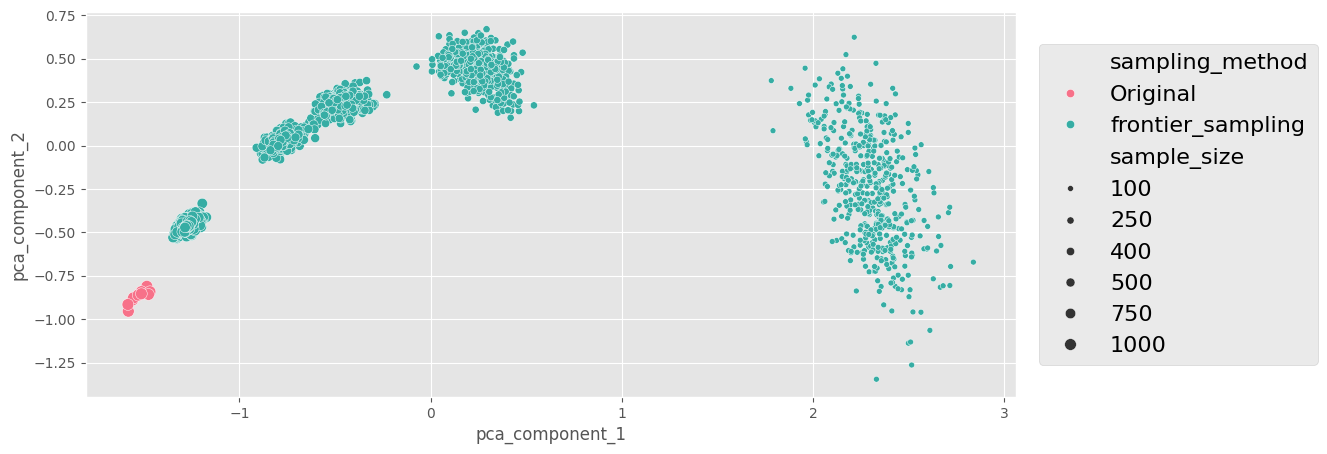

In [11]:
plt.style.use('ggplot')
plt.figure(figsize=(12,5))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                size = "sample_size", 
                hue = "sampling_method", 
                palette = "husl")
plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
            loc="center left", borderaxespad=0.)

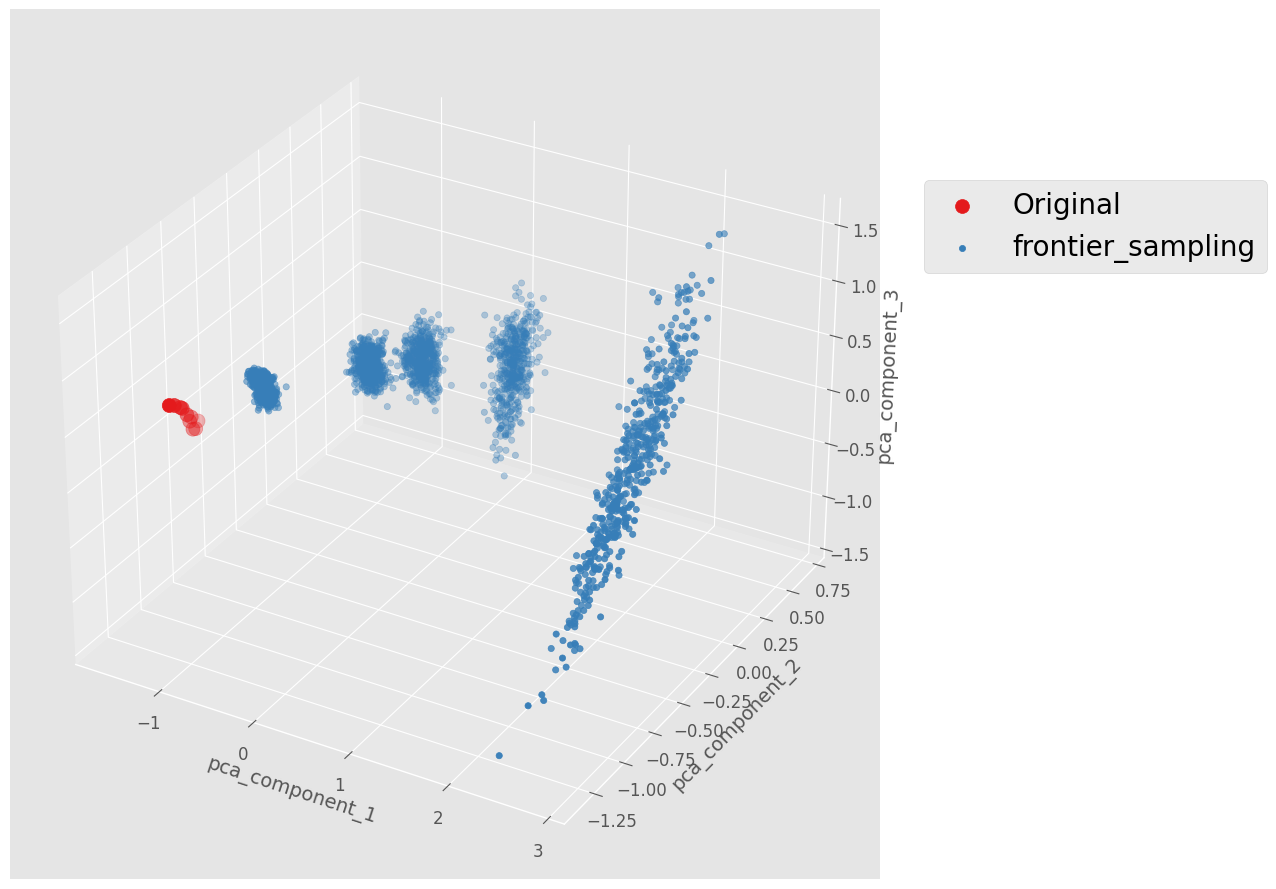

In [12]:
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

plt.rc('xtick', labelsize = 12) 
fig = plt.figure(figsize = (14, 9))
ax = fig.add_subplot(111, projection='3d')

ax.set_prop_cycle(color=plt.cm.Set1.colors)

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']


for method in m.unique():  
    if method == "Original":
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method, s = 100)
    else:
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method)

ax.legend(fontsize = 20, bbox_to_anchor=(1.05, 0.75), 
            loc="center left", borderaxespad=0.)

ax.set_xlabel('pca_component_1', fontsize = 14)
ax.set_ylabel('pca_component_2', fontsize = 14)
ax.set_zlabel('pca_component_3', fontsize = 14)

plt.tight_layout()
plt.show()

In [13]:
df_pca.to_csv('data/fs_serial/pca_ba_fs_m1.csv')

## m=2

In [ ]:
graph_list = []

av_degree = 10  
m = int(av_degree / 2)
random.seed(42)

for i in range(10):
    seed = random.randint(1, 1000000)
    G = nx.barabasi_albert_graph(n = 1000, m = m, seed=seed)
    graph_list.append(G)

In [3]:
och = st.Samnet_ochestrator(graph_list=graph_list)

In [4]:
och.sample_genesis(sampling_methods_list=[frontier_sampling], 
                    sample_sizes=[100,250,400,500,750], runs=50)

Sampling Graphs: 100%|██████████| 2500/2500 [00:02<00:00, 849.42it/s] 


In [5]:
#func_list = [degree_info]

func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics):
        func_list.append(obj)

In [6]:
func_list.pop(9)
func_list.pop(8)
func_list.pop(12)
func_list.pop(12)

<function samnet.metrics.spectral_distance_info(graph, shannon_bin=0.1, n_moments=1, *args, **kwargs)>

In [7]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/fs_serial/swp/')

Metric 13/13 (transitivity): 100%|██████████| 2510/2510 [00:01<00:00, 2054.41it/s]


,graph_id,sampling_method,sample_size,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,betweenness_info_moment_4,betweenness_info_shannon,...,kcore_info_moment_3,kcore_info_moment_4,kcore_info_shannon,local_efficiency,pagerank_info_moment_1,pagerank_info_moment_2,pagerank_info_moment_3,pagerank_info_moment_4,pagerank_info_shannon,transitivity
0,0,Original,1000,-0.063850,2.968539,0.001972,0.000050,0.000003,2.213578e-07,0.000000,...,125.000000,625.000000,0.000000,0.057844,0.001000,0.000002,7.577125e-09,5.095966e-11,0.0,0.031697
1,1,Original,1000,-0.050857,2.974767,0.001979,0.000057,0.000005,5.176923e-07,0.020814,...,125.000000,625.000000,0.000000,0.062587,0.001000,0.000002,8.182398e-09,6.564935e-11,0.0,0.033424
2,2,Original,1000,-0.068383,2.990032,0.001994,0.000038,0.000002,7.878403e-08,0.000000,...,125.000000,625.000000,0.000000,0.046354,0.001000,0.000002,5.946987e-09,3.132128e-11,0.0,0.028673
3,3,Original,1000,-0.066000,2.969746,0.001974,0.000049,0.000003,2.277131e-07,0.000000,...,125.000000,625.000000,0.000000,0.056403,0.001000,0.000002,7.354968e-09,4.884505e-11,0.0,0.030103
4,4,Original,1000,-0.056677,2.982727,0.001987,0.000045,0.000003,1.787958e-07,0.000000,...,125.000000,625.000000,0.000000,0.049750,0.001000,0.000002,6.486866e-09,3.821083e-11,0.0,0.028722
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2505,9,frontier_sampling,750,-0.041891,2.975615,0.002641,0.000064,0.000004,2.602811e-07,0.000000,...,114.704000,563.565333,0.712567,0.056712,0.001333,0.000003,1.335481e-08,9.199984e-11,0.0,0.035775
2506,9,frontier_sampling,750,-0.045782,2.957415,0.002617,0.000066,0.000004,2.999149e-07,0.014657,...,116.260000,572.716000,0.632222,0.056611,0.001333,0.000003,1.363879e-08,9.644184e-11,0.0,0.035203
2507,9,frontier_sampling,750,-0.048341,2.966530,0.002629,0.000065,0.000004,2.698672e-07,0.000000,...,115.150667,566.396000,0.693008,0.059709,0.001333,0.000003,1.360583e-08,9.557982e-11,0.0,0.035923
2508,9,frontier_sampling,750,-0.045257,2.971219,0.002635,0.000066,0.000004,2.760808e-07,0.000000,...,115.592000,568.805333,0.666620,0.059008,0.001333,0.000003,1.366044e-08,9.567973e-11,0.0,0.036060


In [9]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/fs_serial/swp/', output_filename='combined_metrics_m2.csv'
)

Successfully combined 13 files into 'data/fs_serial/swp/combined_metrics_m2.csv' (2510 rows, 44 columns).


In [10]:
df = pd.read_csv('data/fs_serial/combined_metrics_m2.csv')

In [11]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 85.5%
PCA Component 2 EVR: 7.0%
PCA Component 3 EVR: 4.0%


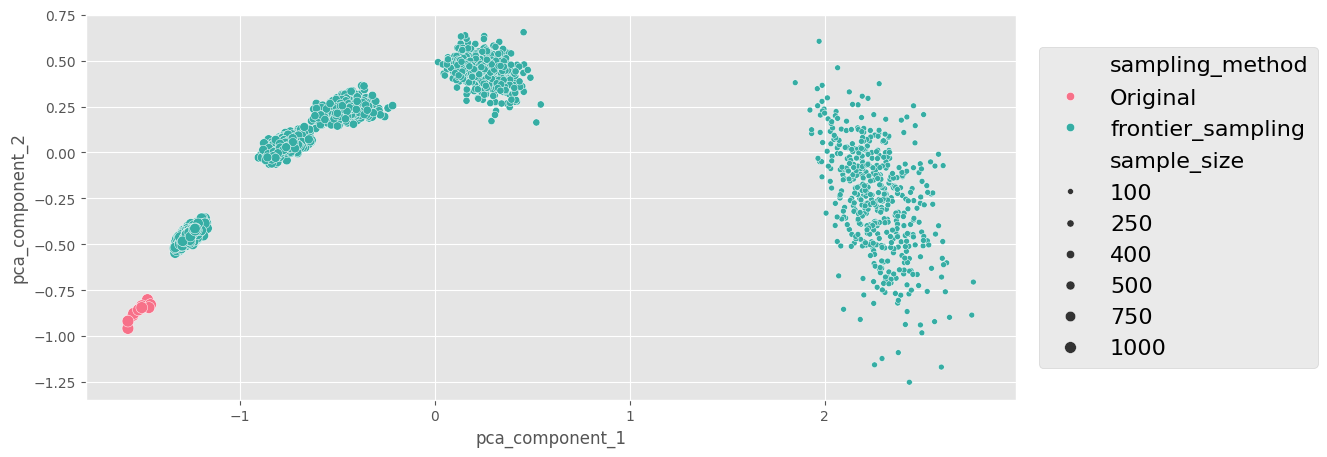

In [12]:
plt.style.use('ggplot')
plt.figure(figsize=(12,5))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                size = "sample_size", 
                hue = "sampling_method", 
                palette = "husl")
plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
            loc="center left", borderaxespad=0.)

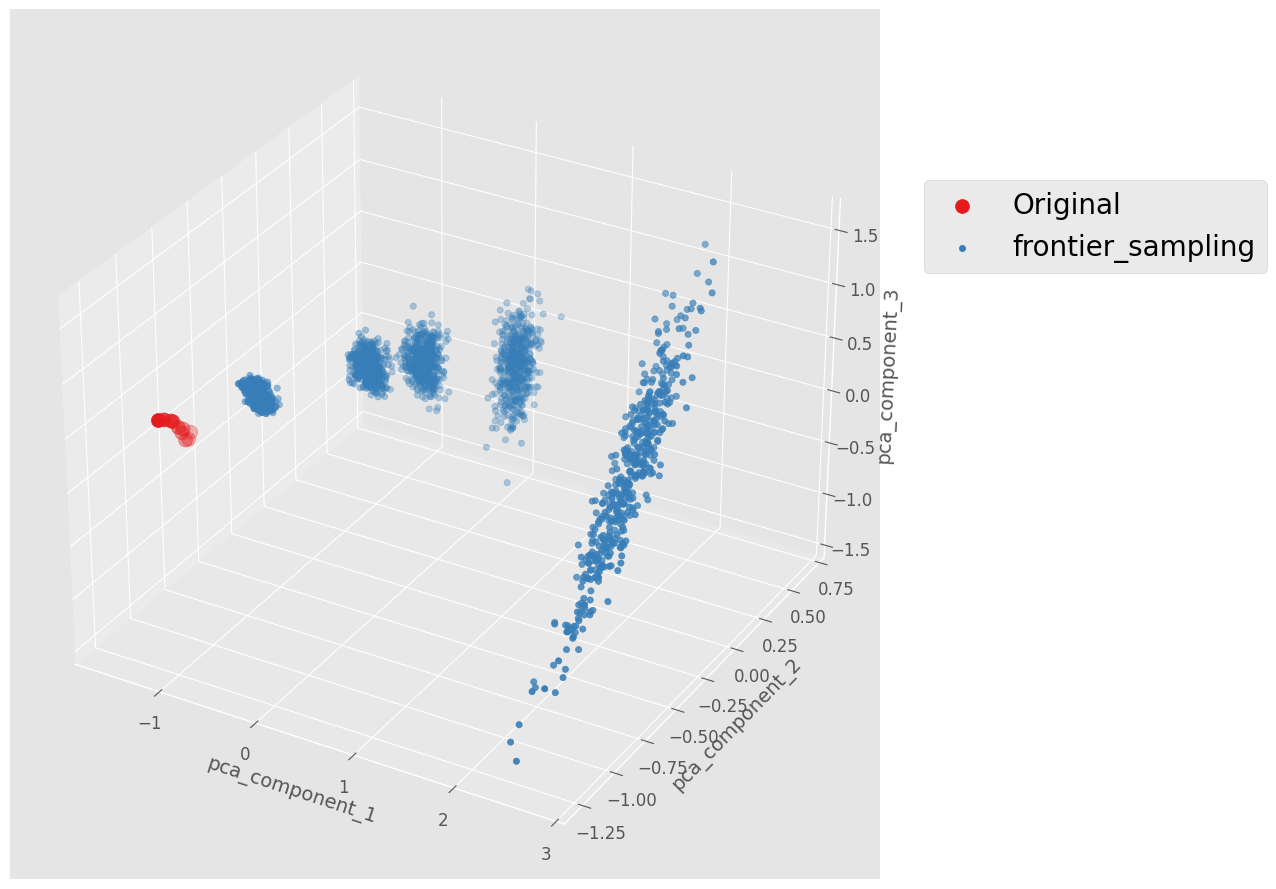

In [13]:
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

plt.rc('xtick', labelsize = 12) 
fig = plt.figure(figsize = (14, 9))
ax = fig.add_subplot(111, projection='3d')

ax.set_prop_cycle(color=plt.cm.Set1.colors)

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']


for method in m.unique():  
    if method == "Original":
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method, s = 100)
    else:
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method)

ax.legend(fontsize = 20, bbox_to_anchor=(1.05, 0.75), 
            loc="center left", borderaxespad=0.)

ax.set_xlabel('pca_component_1', fontsize = 14)
ax.set_ylabel('pca_component_2', fontsize = 14)
ax.set_zlabel('pca_component_3', fontsize = 14)

plt.tight_layout()
plt.show()

In [14]:
df_pca.to_csv('data/fs_serial/pca_ba_fs_m2.csv')

## m=3

In [ ]:
graph_list = []

av_degree = 10  
m = int(av_degree / 2)
random.seed(42)

for i in range(10):
    seed = random.randint(1, 1000000)
    G = nx.barabasi_albert_graph(n = 1000, m = m, seed=seed)
    graph_list.append(G)

In [3]:
och = st.Samnet_ochestrator(graph_list=graph_list)

In [4]:
och.sample_genesis(sampling_methods_list=[frontier_sampling], 
                    sample_sizes=[100,250,400,500,750], runs=50)

Sampling Graphs: 100%|██████████| 2500/2500 [00:02<00:00, 835.32it/s] 


In [5]:
#func_list = [degree_info]

func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics):
        func_list.append(obj)

In [6]:
func_list.pop(9)
func_list.pop(8)
func_list.pop(12)
func_list.pop(12)

<function samnet.metrics.spectral_distance_info(graph, shannon_bin=0.1, n_moments=1, *args, **kwargs)>

In [7]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/fs_serial/swp/')

Metric 13/13 (transitivity): 100%|██████████| 2510/2510 [00:01<00:00, 2027.43it/s]


,graph_id,sampling_method,sample_size,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,betweenness_info_moment_4,betweenness_info_shannon,...,kcore_info_moment_3,kcore_info_moment_4,kcore_info_shannon,local_efficiency,pagerank_info_moment_1,pagerank_info_moment_2,pagerank_info_moment_3,pagerank_info_moment_4,pagerank_info_shannon,transitivity
0,0,Original,1000,-0.063850,2.968539,0.001972,0.000050,0.000003,2.213578e-07,0.000000,...,125.000000,625.000000,0.000000,0.057844,0.001000,0.000002,7.577125e-09,5.095966e-11,0.0,0.031697
1,1,Original,1000,-0.050857,2.974767,0.001979,0.000057,0.000005,5.176923e-07,0.020814,...,125.000000,625.000000,0.000000,0.062587,0.001000,0.000002,8.182398e-09,6.564935e-11,0.0,0.033424
2,2,Original,1000,-0.068383,2.990032,0.001994,0.000038,0.000002,7.878403e-08,0.000000,...,125.000000,625.000000,0.000000,0.046354,0.001000,0.000002,5.946987e-09,3.132128e-11,0.0,0.028673
3,3,Original,1000,-0.066000,2.969746,0.001974,0.000049,0.000003,2.277131e-07,0.000000,...,125.000000,625.000000,0.000000,0.056403,0.001000,0.000002,7.354968e-09,4.884505e-11,0.0,0.030103
4,4,Original,1000,-0.056677,2.982727,0.001987,0.000045,0.000003,1.787958e-07,0.000000,...,125.000000,625.000000,0.000000,0.049750,0.001000,0.000002,6.486866e-09,3.821083e-11,0.0,0.028722
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2505,9,frontier_sampling,750,-0.038440,2.972860,0.002638,0.000065,0.000004,2.851805e-07,0.000000,...,116.288000,573.344000,0.647620,0.056179,0.001333,0.000003,1.306303e-08,9.022778e-11,0.0,0.036302
2506,9,frontier_sampling,750,-0.038835,2.964461,0.002626,0.000067,0.000004,3.074942e-07,0.014657,...,116.981333,577.341333,0.608057,0.055277,0.001333,0.000003,1.344899e-08,9.454678e-11,0.0,0.035728
2507,9,frontier_sampling,750,-0.037631,2.970873,0.002635,0.000064,0.000004,2.819424e-07,0.014657,...,117.388000,579.801333,0.587307,0.054983,0.001333,0.000003,1.299703e-08,8.921388e-11,0.0,0.035578
2508,9,frontier_sampling,750,-0.046093,2.962912,0.002624,0.000067,0.000004,3.151306e-07,0.014657,...,116.281333,573.172000,0.643735,0.058066,0.001333,0.000003,1.370461e-08,9.745579e-11,0.0,0.035925


In [8]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/fs_serial/swp/', output_filename='combined_metrics_m3.csv'
)

Successfully combined 13 files into 'data/fs_serial/swp/combined_metrics_m3.csv' (2510 rows, 44 columns).


In [9]:
df = pd.read_csv('data/fs_serial/combined_metrics_m3.csv')

In [10]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 85.7%
PCA Component 2 EVR: 7.0%
PCA Component 3 EVR: 3.8%


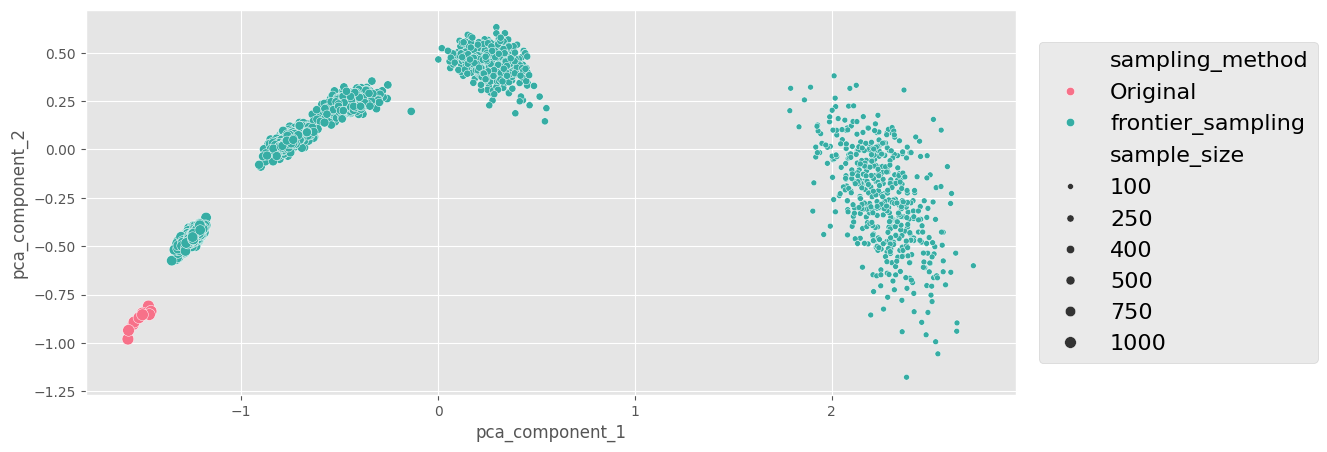

In [11]:
plt.style.use('ggplot')
plt.figure(figsize=(12,5))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                size = "sample_size", 
                hue = "sampling_method", 
                palette = "husl")
plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
            loc="center left", borderaxespad=0.)

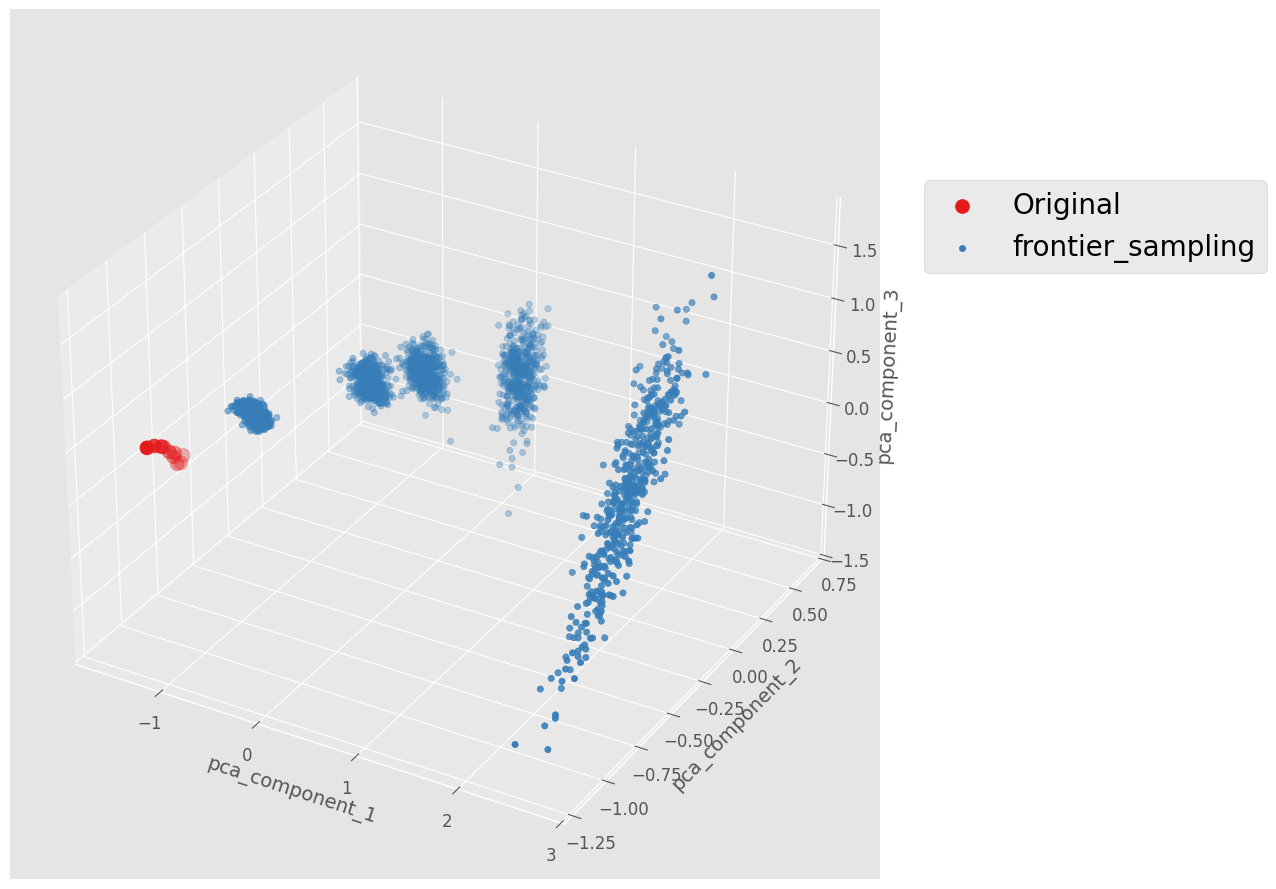

In [12]:
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

plt.rc('xtick', labelsize = 12) 
fig = plt.figure(figsize = (14, 9))
ax = fig.add_subplot(111, projection='3d')

ax.set_prop_cycle(color=plt.cm.Set1.colors)

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']


for method in m.unique():  
    if method == "Original":
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method, s = 100)
    else:
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method)

ax.legend(fontsize = 20, bbox_to_anchor=(1.05, 0.75), 
            loc="center left", borderaxespad=0.)

ax.set_xlabel('pca_component_1', fontsize = 14)
ax.set_ylabel('pca_component_2', fontsize = 14)
ax.set_zlabel('pca_component_3', fontsize = 14)

plt.tight_layout()
plt.show()

In [ ]:
df_pca.to_csv('data/fs_serial/pca_ba_fs_m3.csv')

## m=4

In [2]:
graph_list = []

av_degree = 10  
m = int(av_degree / 2)
random.seed(42)

for i in range(10):
    seed = random.randint(1, 1000000)
    G = nx.barabasi_albert_graph(n = 1000, m = m, seed=seed)
    graph_list.append(G)

In [3]:
och = st.Samnet_ochestrator(graph_list=graph_list)

In [4]:
och.sample_genesis(sampling_methods_list=[frontier_sampling], 
                    sample_sizes=[100,250,400,500,750], runs=50)

Sampling Graphs: 100%|██████████| 2500/2500 [00:02<00:00, 839.89it/s] 


In [5]:
#func_list = [degree_info]

func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics):
        func_list.append(obj)

In [6]:
func_list.pop(9)
func_list.pop(8)
func_list.pop(12)
func_list.pop(12)

<function samnet.metrics.spectral_distance_info(graph, shannon_bin=0.1, n_moments=1, *args, **kwargs)>

In [7]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/fs_serial/swp/')

Metric 13/13 (transitivity): 100%|██████████| 2510/2510 [00:01<00:00, 2040.39it/s]


,graph_id,sampling_method,sample_size,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,betweenness_info_moment_4,betweenness_info_shannon,...,kcore_info_moment_3,kcore_info_moment_4,kcore_info_shannon,local_efficiency,pagerank_info_moment_1,pagerank_info_moment_2,pagerank_info_moment_3,pagerank_info_moment_4,pagerank_info_shannon,transitivity
0,0,Original,1000,-0.063850,2.968539,0.001972,0.000050,0.000003,2.213578e-07,0.000000,...,125.000000,625.000000,0.000000,0.057844,0.001000,0.000002,7.577125e-09,5.095966e-11,0.0,0.031697
1,1,Original,1000,-0.050857,2.974767,0.001979,0.000057,0.000005,5.176923e-07,0.020814,...,125.000000,625.000000,0.000000,0.062587,0.001000,0.000002,8.182398e-09,6.564935e-11,0.0,0.033424
2,2,Original,1000,-0.068383,2.990032,0.001994,0.000038,0.000002,7.878403e-08,0.000000,...,125.000000,625.000000,0.000000,0.046354,0.001000,0.000002,5.946987e-09,3.132128e-11,0.0,0.028673
3,3,Original,1000,-0.066000,2.969746,0.001974,0.000049,0.000003,2.277131e-07,0.000000,...,125.000000,625.000000,0.000000,0.056403,0.001000,0.000002,7.354968e-09,4.884505e-11,0.0,0.030103
4,4,Original,1000,-0.056677,2.982727,0.001987,0.000045,0.000003,1.787958e-07,0.000000,...,125.000000,625.000000,0.000000,0.049750,0.001000,0.000002,6.486866e-09,3.821083e-11,0.0,0.028722
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2505,9,frontier_sampling,750,-0.037587,2.964255,0.002626,0.000064,0.000003,2.395541e-07,0.000000,...,116.178667,572.224000,0.635944,0.056962,0.001333,0.000003,1.301316e-08,8.768844e-11,0.0,0.036426
2506,9,frontier_sampling,750,-0.052413,2.973177,0.002638,0.000066,0.000004,2.618923e-07,0.000000,...,113.357333,555.941333,0.784893,0.055813,0.001333,0.000003,1.384606e-08,9.591112e-11,0.0,0.035485
2507,9,frontier_sampling,750,-0.044709,2.973465,0.002638,0.000064,0.000004,2.918821e-07,0.014657,...,115.290667,566.984000,0.682761,0.055194,0.001333,0.000003,1.313690e-08,9.078243e-11,0.0,0.035823
2508,9,frontier_sampling,750,-0.048786,2.971137,0.002635,0.000065,0.000004,2.968047e-07,0.014657,...,114.489333,562.657333,0.732264,0.056352,0.001333,0.000003,1.356004e-08,9.532697e-11,0.0,0.035217


In [8]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/fs_serial/swp/', output_filename='combined_metrics_m4.csv'
)

Successfully combined 13 files into 'data/fs_serial/swp/combined_metrics_m4.csv' (2510 rows, 44 columns).


In [9]:
df = pd.read_csv('data/fs_serial/combined_metrics_m4.csv')

In [10]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 85.0%
PCA Component 2 EVR: 7.1%
PCA Component 3 EVR: 4.1%


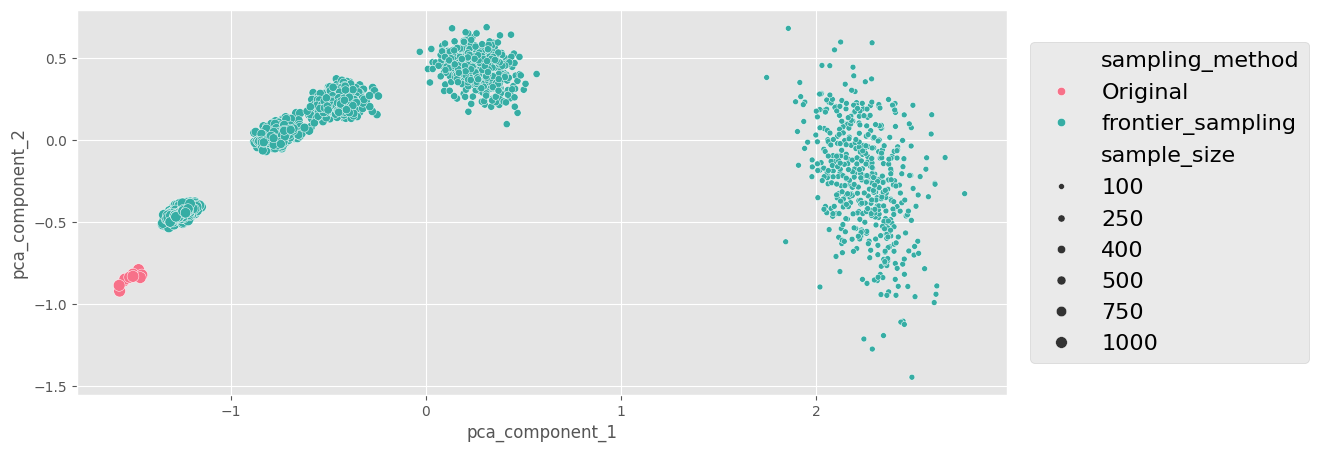

In [11]:
plt.style.use('ggplot')
plt.figure(figsize=(12,5))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                size = "sample_size", 
                hue = "sampling_method", 
                palette = "husl")
plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
            loc="center left", borderaxespad=0.)

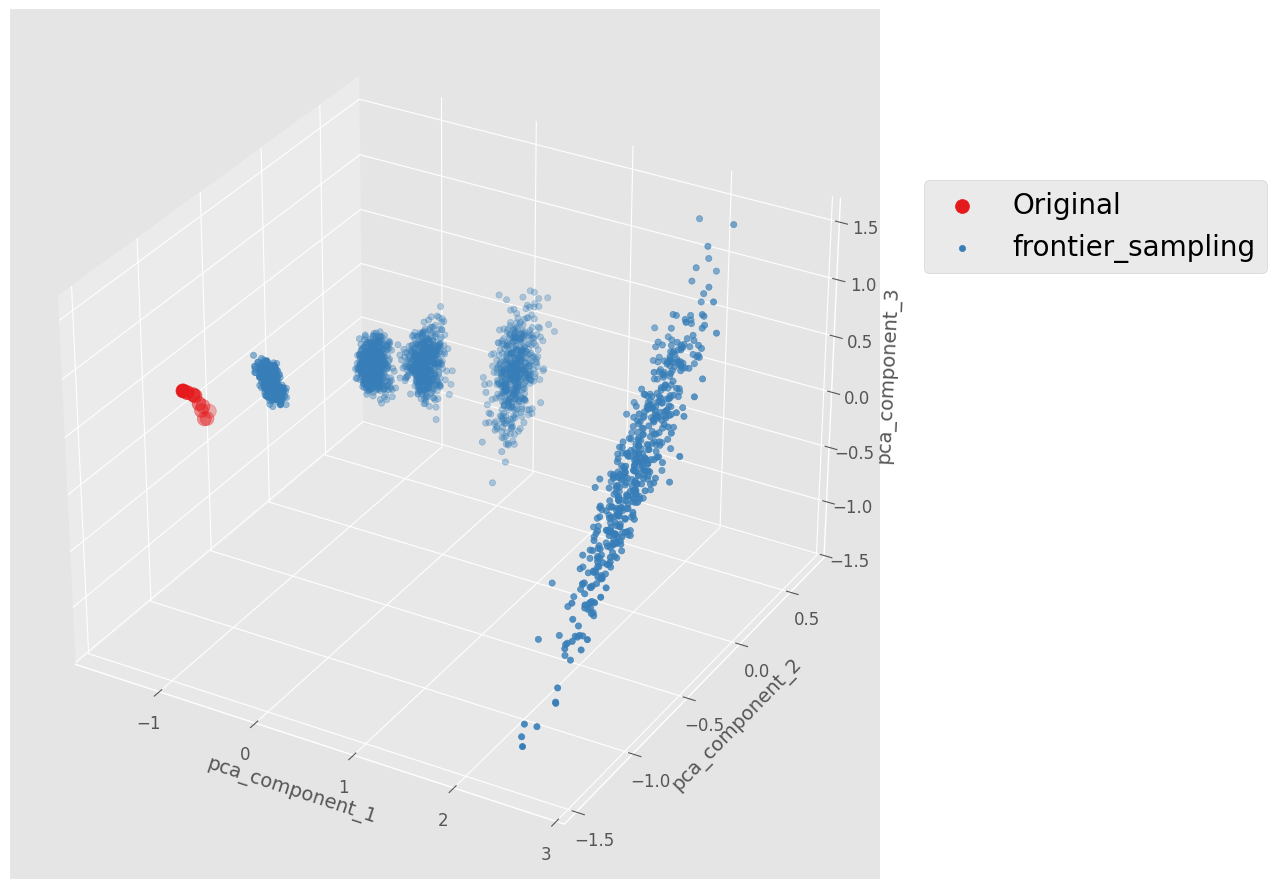

In [12]:
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

plt.rc('xtick', labelsize = 12) 
fig = plt.figure(figsize = (14, 9))
ax = fig.add_subplot(111, projection='3d')

ax.set_prop_cycle(color=plt.cm.Set1.colors)

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']


for method in m.unique():  
    if method == "Original":
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method, s = 100)
    else:
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method)

ax.legend(fontsize = 20, bbox_to_anchor=(1.05, 0.75), 
            loc="center left", borderaxespad=0.)

ax.set_xlabel('pca_component_1', fontsize = 14)
ax.set_ylabel('pca_component_2', fontsize = 14)
ax.set_zlabel('pca_component_3', fontsize = 14)

plt.tight_layout()
plt.show()

In [13]:
df_pca.to_csv('data/fs_serial/pca_ba_fs_m4.csv')

## m=5

In [2]:
graph_list = []

av_degree = 10  
m = int(av_degree / 2)
random.seed(42)

for i in range(10):
    seed = random.randint(1, 1000000)
    G = nx.barabasi_albert_graph(n = 1000, m = m, seed=seed)
    graph_list.append(G)

In [3]:
och = st.Samnet_ochestrator(graph_list=graph_list)

In [4]:
och.sample_genesis(sampling_methods_list=[frontier_sampling], 
                    sample_sizes=[100,250,400,500,750], runs=50)

Sampling Graphs: 100%|██████████| 2500/2500 [00:03<00:00, 822.37it/s] 


In [5]:
#func_list = [degree_info]

func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics):
        func_list.append(obj)

In [6]:
func_list.pop(9)
func_list.pop(8)
func_list.pop(12)
func_list.pop(12)

<function samnet.metrics.spectral_distance_info(graph, shannon_bin=0.1, n_moments=1, *args, **kwargs)>

In [7]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/fs_serial/swp/')

Metric 13/13 (transitivity): 100%|██████████| 2510/2510 [00:01<00:00, 2089.34it/s]


,graph_id,sampling_method,sample_size,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,betweenness_info_moment_4,betweenness_info_shannon,...,kcore_info_moment_3,kcore_info_moment_4,kcore_info_shannon,local_efficiency,pagerank_info_moment_1,pagerank_info_moment_2,pagerank_info_moment_3,pagerank_info_moment_4,pagerank_info_shannon,transitivity
0,0,Original,1000,-0.063850,2.968539,0.001972,0.000050,0.000003,2.213578e-07,0.000000,...,125.000000,625.000000,0.000000,0.057844,0.001000,0.000002,7.577125e-09,5.095966e-11,0.0,0.031697
1,1,Original,1000,-0.050857,2.974767,0.001979,0.000057,0.000005,5.176923e-07,0.020814,...,125.000000,625.000000,0.000000,0.062587,0.001000,0.000002,8.182398e-09,6.564935e-11,0.0,0.033424
2,2,Original,1000,-0.068383,2.990032,0.001994,0.000038,0.000002,7.878403e-08,0.000000,...,125.000000,625.000000,0.000000,0.046354,0.001000,0.000002,5.946987e-09,3.132128e-11,0.0,0.028673
3,3,Original,1000,-0.066000,2.969746,0.001974,0.000049,0.000003,2.277131e-07,0.000000,...,125.000000,625.000000,0.000000,0.056403,0.001000,0.000002,7.354968e-09,4.884505e-11,0.0,0.030103
4,4,Original,1000,-0.056677,2.982727,0.001987,0.000045,0.000003,1.787958e-07,0.000000,...,125.000000,625.000000,0.000000,0.049750,0.001000,0.000002,6.486866e-09,3.821083e-11,0.0,0.028722
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2505,9,frontier_sampling,750,-0.055944,2.946766,0.002603,0.000068,0.000004,3.138657e-07,0.000000,...,117.541333,580.922667,0.575754,0.058810,0.001333,0.000003,1.416592e-08,1.023131e-10,0.0,0.035372
2506,9,frontier_sampling,750,-0.049320,2.963222,0.002625,0.000067,0.000004,3.053726e-07,0.014657,...,116.749333,576.458667,0.624371,0.060071,0.001333,0.000003,1.388279e-08,9.961029e-11,0.0,0.036014
2507,9,frontier_sampling,750,-0.041094,2.964276,0.002626,0.000066,0.000004,3.191893e-07,0.000000,...,117.306667,579.309333,0.591514,0.059360,0.001333,0.000003,1.348435e-08,9.655059e-11,0.0,0.036827
2508,9,frontier_sampling,750,-0.052685,2.961257,0.002622,0.000067,0.000004,2.911945e-07,0.000000,...,114.650667,562.850667,0.695463,0.059277,0.001333,0.000003,1.414309e-08,1.009018e-10,0.0,0.036033


In [8]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/fs_serial/swp/', output_filename='combined_metrics_m5.csv'
)

Successfully combined 13 files into 'data/fs_serial/swp/combined_metrics_m5.csv' (2510 rows, 44 columns).


In [9]:
df = pd.read_csv('data/fs_serial/combined_metrics_m5.csv')

In [10]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 85.4%
PCA Component 2 EVR: 6.9%
PCA Component 3 EVR: 4.0%


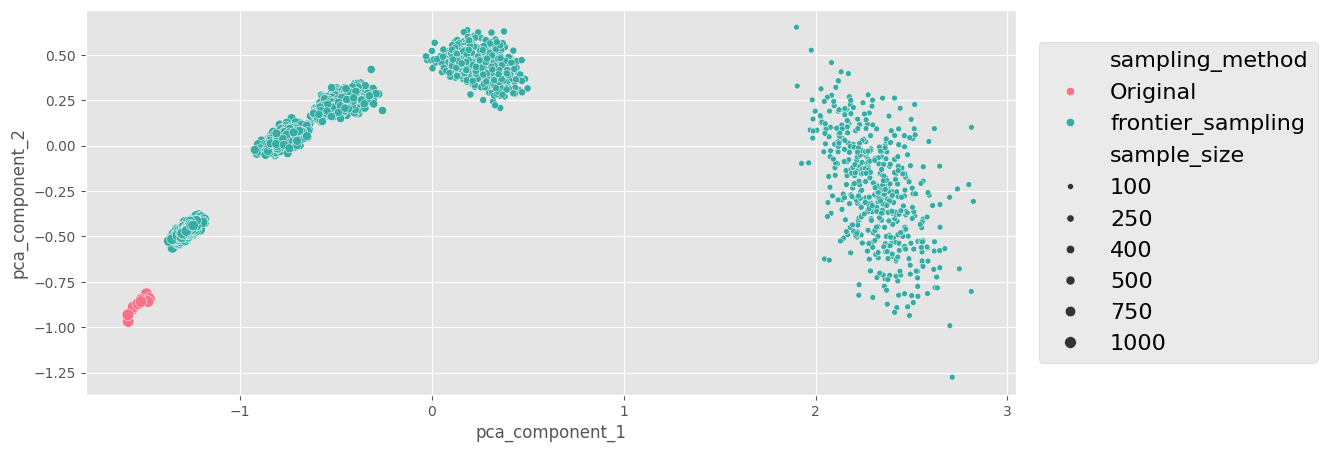

In [11]:
plt.style.use('ggplot')
plt.figure(figsize=(12,5))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                size = "sample_size", 
                hue = "sampling_method", 
                palette = "husl")
plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
            loc="center left", borderaxespad=0.)

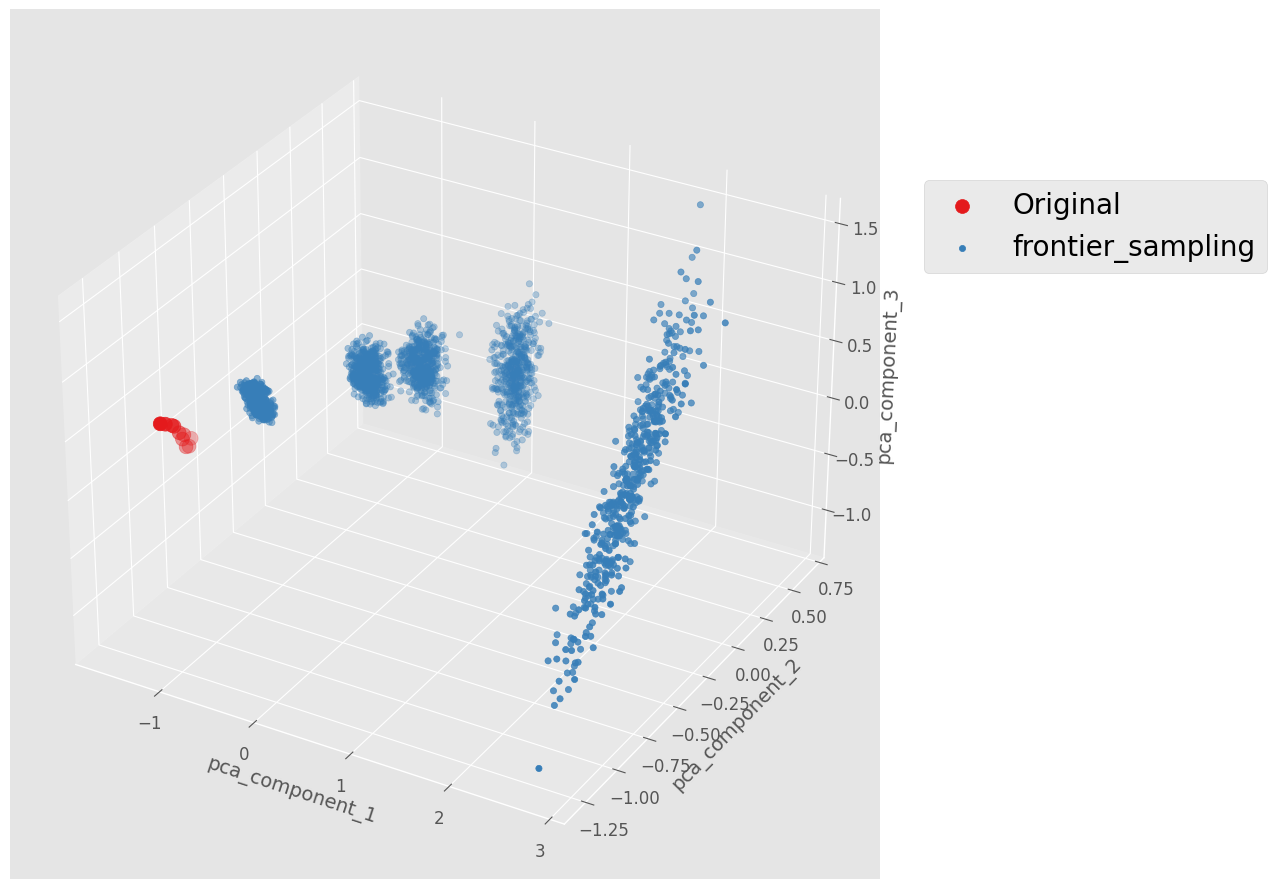

In [12]:
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

plt.rc('xtick', labelsize = 12) 
fig = plt.figure(figsize = (14, 9))
ax = fig.add_subplot(111, projection='3d')

ax.set_prop_cycle(color=plt.cm.Set1.colors)

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']


for method in m.unique():  
    if method == "Original":
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method, s = 100)
    else:
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method)

ax.legend(fontsize = 20, bbox_to_anchor=(1.05, 0.75), 
            loc="center left", borderaxespad=0.)

ax.set_xlabel('pca_component_1', fontsize = 14)
ax.set_ylabel('pca_component_2', fontsize = 14)
ax.set_zlabel('pca_component_3', fontsize = 14)

plt.tight_layout()
plt.show()

In [ ]:
df_pca.to_csv('data/fs_serial/pca_ba_fs_m4.csv')

Conclusions: the difference between m choices is negligible.

# Test: forest fire $p$ factor

## $p$=0.1

In [2]:
graph_list = []

av_degree = 10  
m = int(av_degree / 2)
random.seed(42)

for i in range(10):
    seed = random.randint(1, 1000000)
    G = nx.barabasi_albert_graph(n = 1000, m = m, seed=seed)
    graph_list.append(G)

In [3]:
och = st.Samnet_ochestrator(graph_list=graph_list)

In [4]:
och.sample_genesis(sampling_methods_list=[forest_fire_sampling], 
                    sample_sizes=[100,250,400,500,750], runs=50)

Sampling Graphs: 100%|██████████| 2500/2500 [00:02<00:00, 854.31it/s] 


In [ ]:
func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics):
        func_list.append(obj)

In [6]:
func_list.pop(9)
func_list.pop(8)
func_list.pop(12)
func_list.pop(12)

<function samnet.metrics.spectral_distance_info(graph, shannon_bin=0.1, n_moments=1, *args, **kwargs)>

In [ ]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/ff_serial/swp/')

Metric 13/13 (transitivity): 100%|██████████| 2510/2510 [00:01<00:00, 1880.12it/s]


,graph_id,sampling_method,sample_size,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,betweenness_info_moment_4,betweenness_info_shannon,...,kcore_info_moment_3,kcore_info_moment_4,kcore_info_shannon,local_efficiency,pagerank_info_moment_1,pagerank_info_moment_2,pagerank_info_moment_3,pagerank_info_moment_4,pagerank_info_shannon,transitivity
0,0,Original,1000,-0.063850,2.968539,0.001972,0.000050,0.000003,2.213578e-07,0.000000,...,125.000000,625.000000,0.000000,0.057844,0.001000,0.000002,7.577125e-09,5.095966e-11,0.0,0.031697
1,1,Original,1000,-0.050857,2.974767,0.001979,0.000057,0.000005,5.176923e-07,0.020814,...,125.000000,625.000000,0.000000,0.062587,0.001000,0.000002,8.182398e-09,6.564935e-11,0.0,0.033424
2,2,Original,1000,-0.068383,2.990032,0.001994,0.000038,0.000002,7.878403e-08,0.000000,...,125.000000,625.000000,0.000000,0.046354,0.001000,0.000002,5.946987e-09,3.132128e-11,0.0,0.028673
3,3,Original,1000,-0.066000,2.969746,0.001974,0.000049,0.000003,2.277131e-07,0.000000,...,125.000000,625.000000,0.000000,0.056403,0.001000,0.000002,7.354968e-09,4.884505e-11,0.0,0.030103
4,4,Original,1000,-0.056677,2.982727,0.001987,0.000045,0.000003,1.787958e-07,0.000000,...,125.000000,625.000000,0.000000,0.049750,0.001000,0.000002,6.486866e-09,3.821083e-11,0.0,0.028722
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2505,9,forest_fire_sampling,750,-0.018727,2.980162,0.002647,0.000063,0.000004,2.631917e-07,0.000000,...,119.398667,591.705333,0.471252,0.049977,0.001333,0.000003,1.203124e-08,7.851139e-11,0.0,0.035616
2506,9,forest_fire_sampling,750,-0.021775,2.975601,0.002641,0.000064,0.000004,3.174876e-07,0.014657,...,120.237333,596.712000,0.418928,0.051514,0.001333,0.000003,1.225232e-08,8.445867e-11,0.0,0.035564
2507,9,forest_fire_sampling,750,-0.021242,2.973839,0.002639,0.000063,0.000004,2.513416e-07,0.000000,...,118.406667,585.766667,0.525647,0.054312,0.001333,0.000003,1.218532e-08,8.008723e-11,0.0,0.036638
2508,9,forest_fire_sampling,750,-0.023647,2.969520,0.002633,0.000063,0.000004,2.776349e-07,0.014657,...,121.482667,604.178667,0.330138,0.052503,0.001333,0.000003,1.226897e-08,8.225414e-11,0.0,0.035960


In [ ]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/ff_serial/swp/', output_filename='combined_metrics_p01.csv'
)

Successfully combined 13 files into 'data/fs_serial/swp/combined_metrics_p01.csv' (2510 rows, 44 columns).


In [9]:
df = pd.read_csv('data/ff_serial/combined_metrics_p01.csv')

In [10]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 85.3%
PCA Component 2 EVR: 7.1%
PCA Component 3 EVR: 4.0%


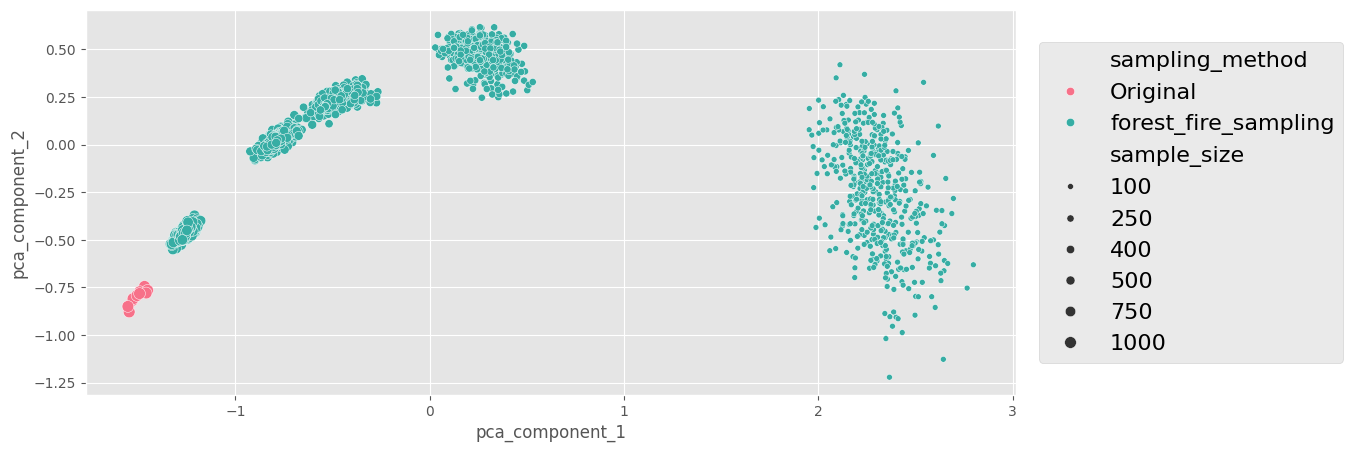

In [11]:
plt.style.use('ggplot')
plt.figure(figsize=(12,5))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                size = "sample_size", 
                hue = "sampling_method", 
                palette = "husl")
plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
            loc="center left", borderaxespad=0.)

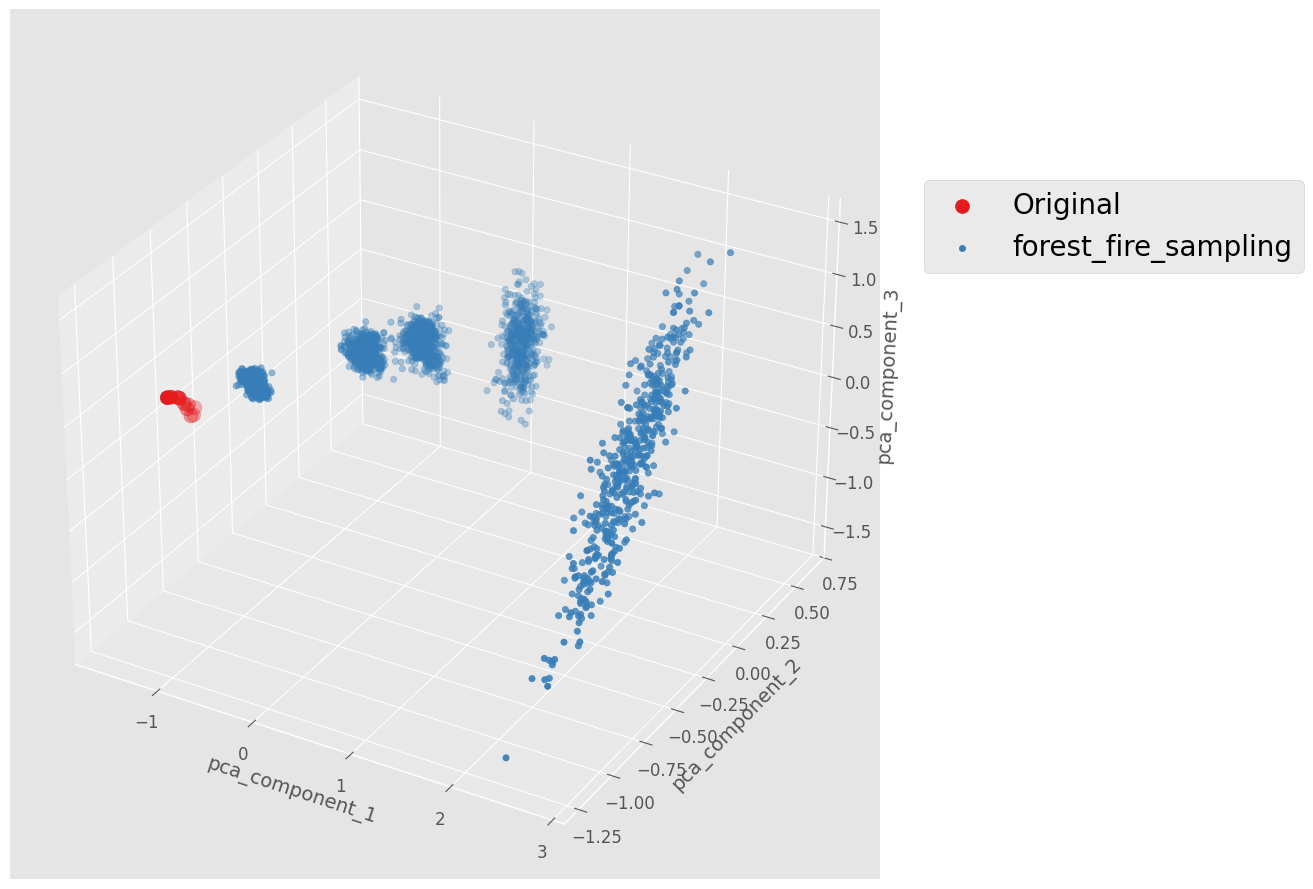

In [12]:
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

plt.rc('xtick', labelsize = 12) 
fig = plt.figure(figsize = (14, 9))
ax = fig.add_subplot(111, projection='3d')

ax.set_prop_cycle(color=plt.cm.Set1.colors)

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']


for method in m.unique():  
    if method == "Original":
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method, s = 100)
    else:
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method)

ax.legend(fontsize = 20, bbox_to_anchor=(1.05, 0.75), 
            loc="center left", borderaxespad=0.)

ax.set_xlabel('pca_component_1', fontsize = 14)
ax.set_ylabel('pca_component_2', fontsize = 14)
ax.set_zlabel('pca_component_3', fontsize = 14)

plt.tight_layout()
plt.show()

## $p$=0.2

In [2]:
graph_list = []

av_degree = 10  
m = int(av_degree / 2)
random.seed(42)

for i in range(10):
    seed = random.randint(1, 1000000)
    G = nx.barabasi_albert_graph(n = 1000, m = m, seed=seed)
    graph_list.append(G)

In [3]:
och = st.Samnet_ochestrator(graph_list=graph_list)

In [4]:
och.sample_genesis(sampling_methods_list=[forest_fire_sampling], 
                    sample_sizes=[100,250,400,500,750], runs=50)

Sampling Graphs: 100%|██████████| 2500/2500 [00:02<00:00, 847.17it/s] 


In [5]:
#func_list = [degree_info]

func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics):
        func_list.append(obj)

In [6]:
func_list.pop(9)
func_list.pop(8)
func_list.pop(12)
func_list.pop(12)

<function samnet.metrics.spectral_distance_info(graph, shannon_bin=0.1, n_moments=1, *args, **kwargs)>

In [7]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/ff_serial/swp/')

Metric 13/13 (transitivity): 100%|██████████| 2510/2510 [00:01<00:00, 2035.91it/s]


,graph_id,sampling_method,sample_size,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,betweenness_info_moment_4,betweenness_info_shannon,...,kcore_info_moment_3,kcore_info_moment_4,kcore_info_shannon,local_efficiency,pagerank_info_moment_1,pagerank_info_moment_2,pagerank_info_moment_3,pagerank_info_moment_4,pagerank_info_shannon,transitivity
0,0,Original,1000,-0.063850,2.968539,0.001972,0.000050,0.000003,2.213578e-07,0.000000,...,125.000000,625.000000,0.000000,0.057844,0.001000,0.000002,7.577125e-09,5.095966e-11,0.0,0.031697
1,1,Original,1000,-0.050857,2.974767,0.001979,0.000057,0.000005,5.176923e-07,0.020814,...,125.000000,625.000000,0.000000,0.062587,0.001000,0.000002,8.182398e-09,6.564935e-11,0.0,0.033424
2,2,Original,1000,-0.068383,2.990032,0.001994,0.000038,0.000002,7.878403e-08,0.000000,...,125.000000,625.000000,0.000000,0.046354,0.001000,0.000002,5.946987e-09,3.132128e-11,0.0,0.028673
3,3,Original,1000,-0.066000,2.969746,0.001974,0.000049,0.000003,2.277131e-07,0.000000,...,125.000000,625.000000,0.000000,0.056403,0.001000,0.000002,7.354968e-09,4.884505e-11,0.0,0.030103
4,4,Original,1000,-0.056677,2.982727,0.001987,0.000045,0.000003,1.787958e-07,0.000000,...,125.000000,625.000000,0.000000,0.049750,0.001000,0.000002,6.486866e-09,3.821083e-11,0.0,0.028722
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2505,9,forest_fire_sampling,750,-0.031599,2.952039,0.002610,0.000062,0.000004,2.785388e-07,0.014657,...,120.800000,599.984000,0.377911,0.053710,0.001333,0.000003,1.243463e-08,8.452739e-11,0.0,0.035596
2506,9,forest_fire_sampling,750,-0.015695,2.973020,0.002638,0.000061,0.000003,2.382854e-07,0.000000,...,120.509333,597.965333,0.389798,0.049725,0.001333,0.000003,1.174523e-08,7.609935e-11,0.0,0.035836
2507,9,forest_fire_sampling,750,-0.023385,2.973248,0.002638,0.000064,0.000004,2.863011e-07,0.000000,...,119.520000,592.568000,0.465463,0.049665,0.001333,0.000003,1.236405e-08,8.309260e-11,0.0,0.034623
2508,9,forest_fire_sampling,750,-0.025824,2.973340,0.002638,0.000064,0.000004,2.868072e-07,0.000000,...,119.010667,589.160000,0.486886,0.051930,0.001333,0.000003,1.246604e-08,8.604606e-11,0.0,0.035565


In [8]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/ff_serial/swp/', output_filename='combined_metrics_p02.csv'
)

Successfully combined 13 files into 'data/ff_serial/swp/combined_metrics_p02.csv' (2510 rows, 44 columns).


In [10]:
df = pd.read_csv('data/ff_serial/combined_metrics_p02.csv')

In [11]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 85.0%
PCA Component 2 EVR: 7.1%
PCA Component 3 EVR: 4.0%


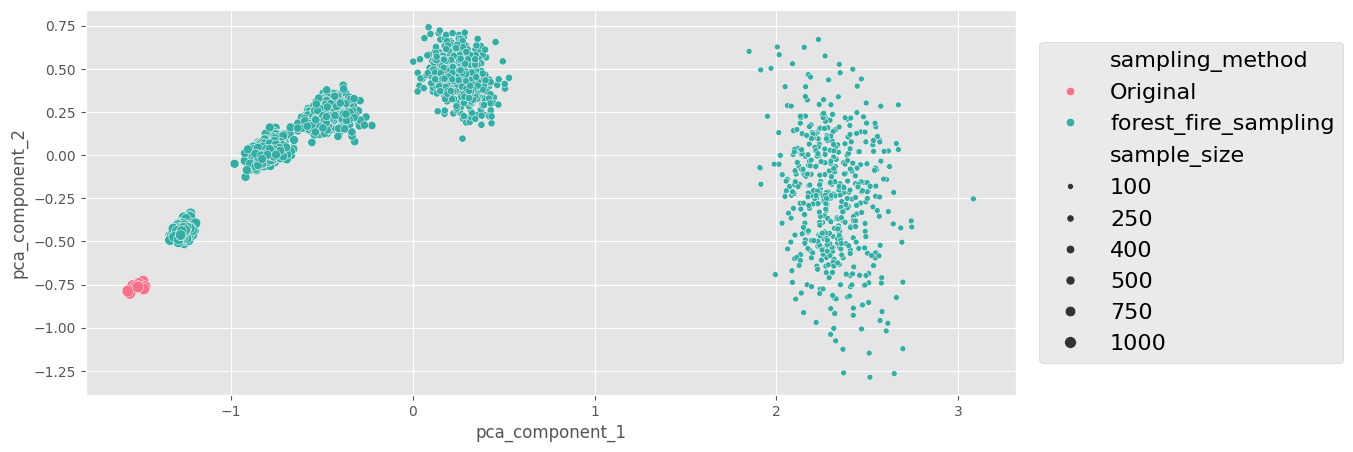

In [12]:
plt.style.use('ggplot')
plt.figure(figsize=(12,5))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                size = "sample_size", 
                hue = "sampling_method", 
                palette = "husl")
plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
            loc="center left", borderaxespad=0.)

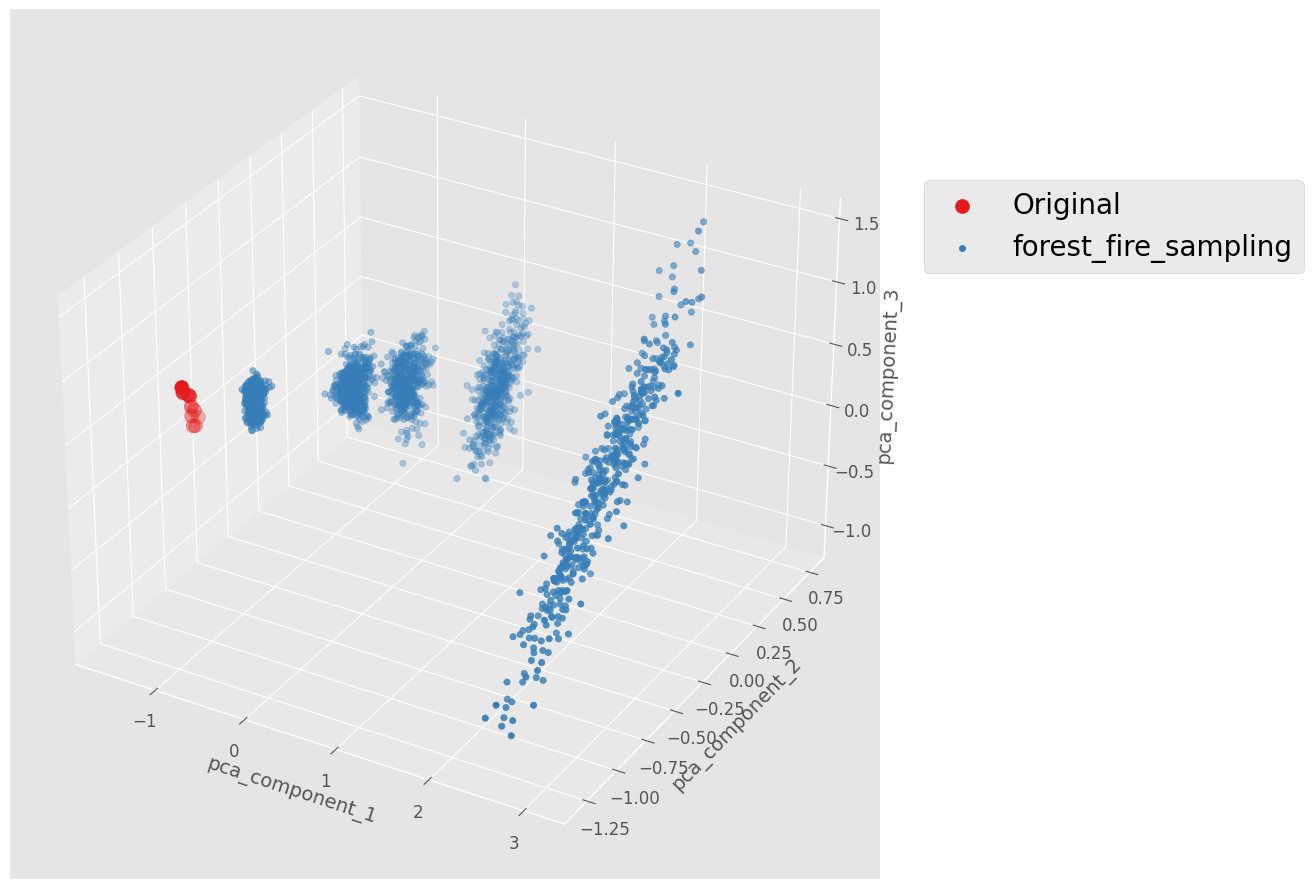

In [13]:
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

plt.rc('xtick', labelsize = 12) 
fig = plt.figure(figsize = (14, 9))
ax = fig.add_subplot(111, projection='3d')

ax.set_prop_cycle(color=plt.cm.Set1.colors)

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']


for method in m.unique():  
    if method == "Original":
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method, s = 100)
    else:
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method)

ax.legend(fontsize = 20, bbox_to_anchor=(1.05, 0.75), 
            loc="center left", borderaxespad=0.)

ax.set_xlabel('pca_component_1', fontsize = 14)
ax.set_ylabel('pca_component_2', fontsize = 14)
ax.set_zlabel('pca_component_3', fontsize = 14)

plt.tight_layout()
plt.show()

## $p$=0.3

In [2]:
graph_list = []

av_degree = 10  
m = int(av_degree / 2)
random.seed(42)

for i in range(10):
    seed = random.randint(1, 1000000)
    G = nx.barabasi_albert_graph(n = 1000, m = m, seed=seed)
    graph_list.append(G)

In [3]:
och = st.Samnet_ochestrator(graph_list=graph_list)

In [4]:
och.sample_genesis(sampling_methods_list=[forest_fire_sampling], 
                    sample_sizes=[100,250,400,500,750], runs=50)

Sampling Graphs: 100%|██████████| 2500/2500 [00:02<00:00, 967.19it/s] 


In [5]:
#func_list = [degree_info]

func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics):
        func_list.append(obj)

In [6]:
func_list.pop(9)
func_list.pop(8)
func_list.pop(12)
func_list.pop(12)

<function samnet.metrics.spectral_distance_info(graph, shannon_bin=0.1, n_moments=1, *args, **kwargs)>

In [7]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/ff_serial/swp/')

Metric 13/13 (transitivity): 100%|██████████| 2510/2510 [00:01<00:00, 1990.38it/s]


,graph_id,sampling_method,sample_size,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,betweenness_info_moment_4,betweenness_info_shannon,...,kcore_info_moment_3,kcore_info_moment_4,kcore_info_shannon,local_efficiency,pagerank_info_moment_1,pagerank_info_moment_2,pagerank_info_moment_3,pagerank_info_moment_4,pagerank_info_shannon,transitivity
0,0,Original,1000,-0.063850,2.968539,0.001972,0.000050,0.000003,2.213578e-07,0.000000,...,125.000000,625.000000,0.000000,0.057844,0.001000,0.000002,7.577125e-09,5.095966e-11,0.0,0.031697
1,1,Original,1000,-0.050857,2.974767,0.001979,0.000057,0.000005,5.176923e-07,0.020814,...,125.000000,625.000000,0.000000,0.062587,0.001000,0.000002,8.182398e-09,6.564935e-11,0.0,0.033424
2,2,Original,1000,-0.068383,2.990032,0.001994,0.000038,0.000002,7.878403e-08,0.000000,...,125.000000,625.000000,0.000000,0.046354,0.001000,0.000002,5.946987e-09,3.132128e-11,0.0,0.028673
3,3,Original,1000,-0.066000,2.969746,0.001974,0.000049,0.000003,2.277131e-07,0.000000,...,125.000000,625.000000,0.000000,0.056403,0.001000,0.000002,7.354968e-09,4.884505e-11,0.0,0.030103
4,4,Original,1000,-0.056677,2.982727,0.001987,0.000045,0.000003,1.787958e-07,0.000000,...,125.000000,625.000000,0.000000,0.049750,0.001000,0.000002,6.486866e-09,3.821083e-11,0.0,0.028722
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2505,9,forest_fire_sampling,750,-0.030877,2.967815,0.002631,0.000062,0.000003,2.337215e-07,0.000000,...,119.381333,591.730667,0.474990,0.055552,0.001333,0.000003,1.238490e-08,8.192225e-11,0.0,0.036574
2506,9,forest_fire_sampling,750,-0.020785,2.977972,0.002644,0.000062,0.000003,2.543238e-07,0.000000,...,118.982667,589.382667,0.498236,0.051055,0.001333,0.000003,1.198119e-08,7.790161e-11,0.0,0.035871
2507,9,forest_fire_sampling,750,-0.028887,2.967413,0.002630,0.000063,0.000004,2.912088e-07,0.000000,...,118.653333,586.933333,0.504332,0.054631,0.001333,0.000003,1.248928e-08,8.578931e-11,0.0,0.036458
2508,9,forest_fire_sampling,750,-0.024501,2.969271,0.002633,0.000063,0.000004,2.689842e-07,0.000000,...,120.528000,598.730667,0.399268,0.051570,0.001333,0.000003,1.228703e-08,8.259342e-11,0.0,0.035516


In [8]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/ff_serial/swp/', output_filename='combined_metrics_p03.csv'
)

Successfully combined 13 files into 'data/ff_serial/swp/combined_metrics_p03.csv' (2510 rows, 44 columns).


In [9]:
df = pd.read_csv('data/ff_serial/combined_metrics_p03.csv')

In [10]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 85.0%
PCA Component 2 EVR: 6.8%
PCA Component 3 EVR: 4.0%


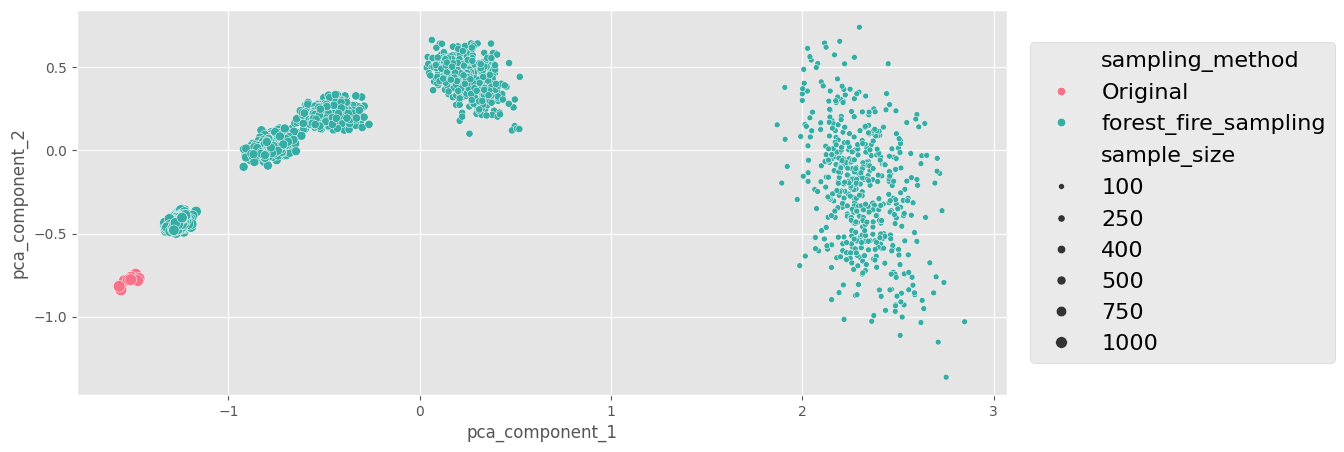

In [11]:
plt.style.use('ggplot')
plt.figure(figsize=(12,5))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                size = "sample_size", 
                hue = "sampling_method", 
                palette = "husl")
plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
            loc="center left", borderaxespad=0.)

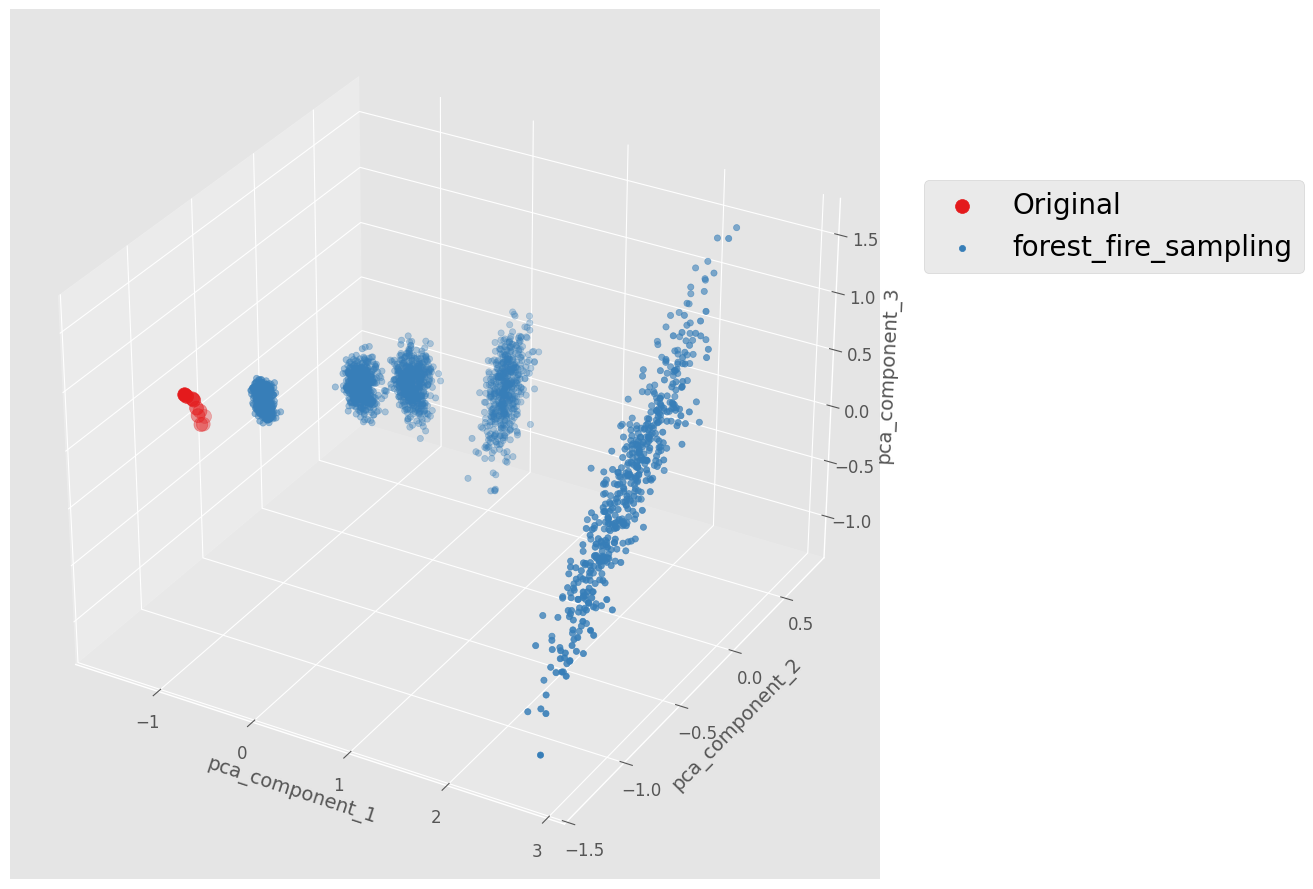

In [12]:
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

plt.rc('xtick', labelsize = 12) 
fig = plt.figure(figsize = (14, 9))
ax = fig.add_subplot(111, projection='3d')

ax.set_prop_cycle(color=plt.cm.Set1.colors)

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']


for method in m.unique():  
    if method == "Original":
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method, s = 100)
    else:
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method)

ax.legend(fontsize = 20, bbox_to_anchor=(1.05, 0.75), 
            loc="center left", borderaxespad=0.)

ax.set_xlabel('pca_component_1', fontsize = 14)
ax.set_ylabel('pca_component_2', fontsize = 14)
ax.set_zlabel('pca_component_3', fontsize = 14)

plt.tight_layout()
plt.show()

## $p$=0.4

In [2]:
graph_list = []

av_degree = 10  
m = int(av_degree / 2)
random.seed(42)

for i in range(10):
    seed = random.randint(1, 1000000)
    G = nx.barabasi_albert_graph(n = 1000, m = m, seed=seed)
    graph_list.append(G)

In [3]:
och = st.Samnet_ochestrator(graph_list=graph_list)

In [4]:
och.sample_genesis(sampling_methods_list=[forest_fire_sampling], 
                    sample_sizes=[100,250,400,500,750], runs=50)

Sampling Graphs: 100%|██████████| 2500/2500 [00:02<00:00, 841.57it/s] 


In [5]:
#func_list = [degree_info]

func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics):
        func_list.append(obj)

In [6]:
func_list.pop(9)
func_list.pop(8)
func_list.pop(12)
func_list.pop(12)

<function samnet.metrics.spectral_distance_info(graph, shannon_bin=0.1, n_moments=1, *args, **kwargs)>

In [7]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/ff_serial/swp/')

Metric 13/13 (transitivity): 100%|██████████| 2510/2510 [00:01<00:00, 2008.22it/s]


,graph_id,sampling_method,sample_size,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,betweenness_info_moment_4,betweenness_info_shannon,...,kcore_info_moment_3,kcore_info_moment_4,kcore_info_shannon,local_efficiency,pagerank_info_moment_1,pagerank_info_moment_2,pagerank_info_moment_3,pagerank_info_moment_4,pagerank_info_shannon,transitivity
0,0,Original,1000,-0.063850,2.968539,0.001972,0.000050,0.000003,2.213578e-07,0.000000,...,125.000000,625.000000,0.000000,0.057844,0.001000,0.000002,7.577125e-09,5.095966e-11,0.0,0.031697
1,1,Original,1000,-0.050857,2.974767,0.001979,0.000057,0.000005,5.176923e-07,0.020814,...,125.000000,625.000000,0.000000,0.062587,0.001000,0.000002,8.182398e-09,6.564935e-11,0.0,0.033424
2,2,Original,1000,-0.068383,2.990032,0.001994,0.000038,0.000002,7.878403e-08,0.000000,...,125.000000,625.000000,0.000000,0.046354,0.001000,0.000002,5.946987e-09,3.132128e-11,0.0,0.028673
3,3,Original,1000,-0.066000,2.969746,0.001974,0.000049,0.000003,2.277131e-07,0.000000,...,125.000000,625.000000,0.000000,0.056403,0.001000,0.000002,7.354968e-09,4.884505e-11,0.0,0.030103
4,4,Original,1000,-0.056677,2.982727,0.001987,0.000045,0.000003,1.787958e-07,0.000000,...,125.000000,625.000000,0.000000,0.049750,0.001000,0.000002,6.486866e-09,3.821083e-11,0.0,0.028722
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2505,9,forest_fire_sampling,750,-0.027054,2.981073,0.002648,0.000064,0.000004,2.816643e-07,0.000000,...,117.940000,583.270667,0.559089,0.053301,0.001333,0.000003,1.264017e-08,8.687622e-11,0.0,0.035984
2506,9,forest_fire_sampling,750,-0.024640,2.983964,0.002652,0.000062,0.000003,2.278152e-07,0.000000,...,118.092000,584.452000,0.553317,0.051954,0.001333,0.000003,1.212986e-08,7.887632e-11,0.0,0.035847
2507,9,forest_fire_sampling,750,-0.019250,2.979567,0.002646,0.000063,0.000004,2.916281e-07,0.014657,...,117.710667,581.921333,0.575889,0.051407,0.001333,0.000003,1.210931e-08,8.076050e-11,0.0,0.036297
2508,9,forest_fire_sampling,750,-0.017448,2.986852,0.002656,0.000059,0.000003,2.100910e-07,0.000000,...,118.356000,585.593333,0.535272,0.050022,0.001333,0.000003,1.158980e-08,7.292530e-11,0.0,0.035054


In [8]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/ff_serial/swp/', output_filename='combined_metrics_p04.csv'
)

Successfully combined 13 files into 'data/ff_serial/swp/combined_metrics_p04.csv' (2510 rows, 44 columns).


In [9]:
df = pd.read_csv('data/ff_serial/combined_metrics_p04.csv')

In [10]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 86.5%
PCA Component 2 EVR: 6.4%
PCA Component 3 EVR: 3.7%


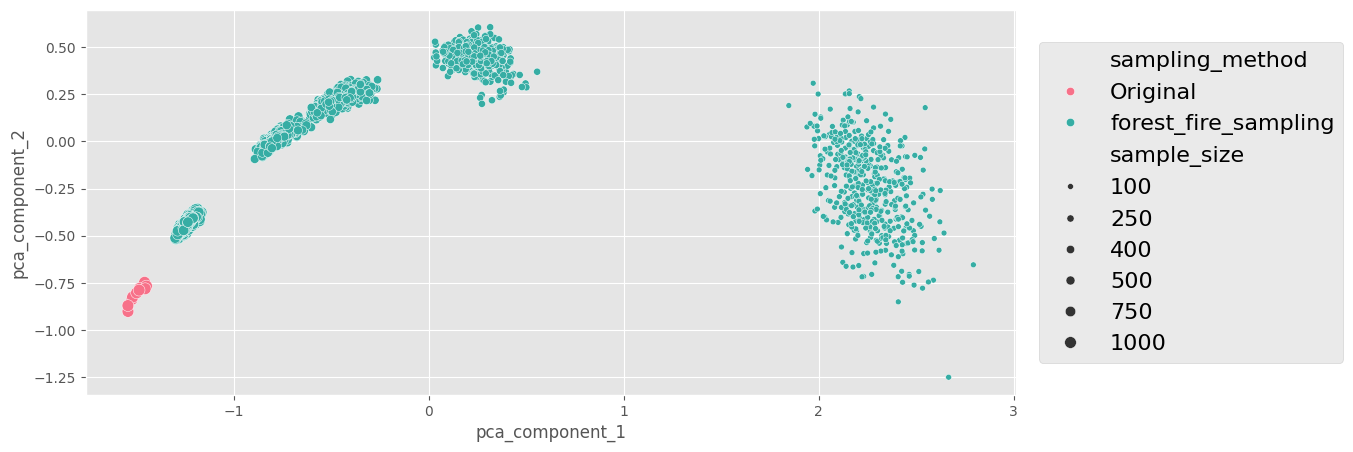

In [11]:
plt.style.use('ggplot')
plt.figure(figsize=(12,5))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                size = "sample_size", 
                hue = "sampling_method", 
                palette = "husl")
plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
            loc="center left", borderaxespad=0.)

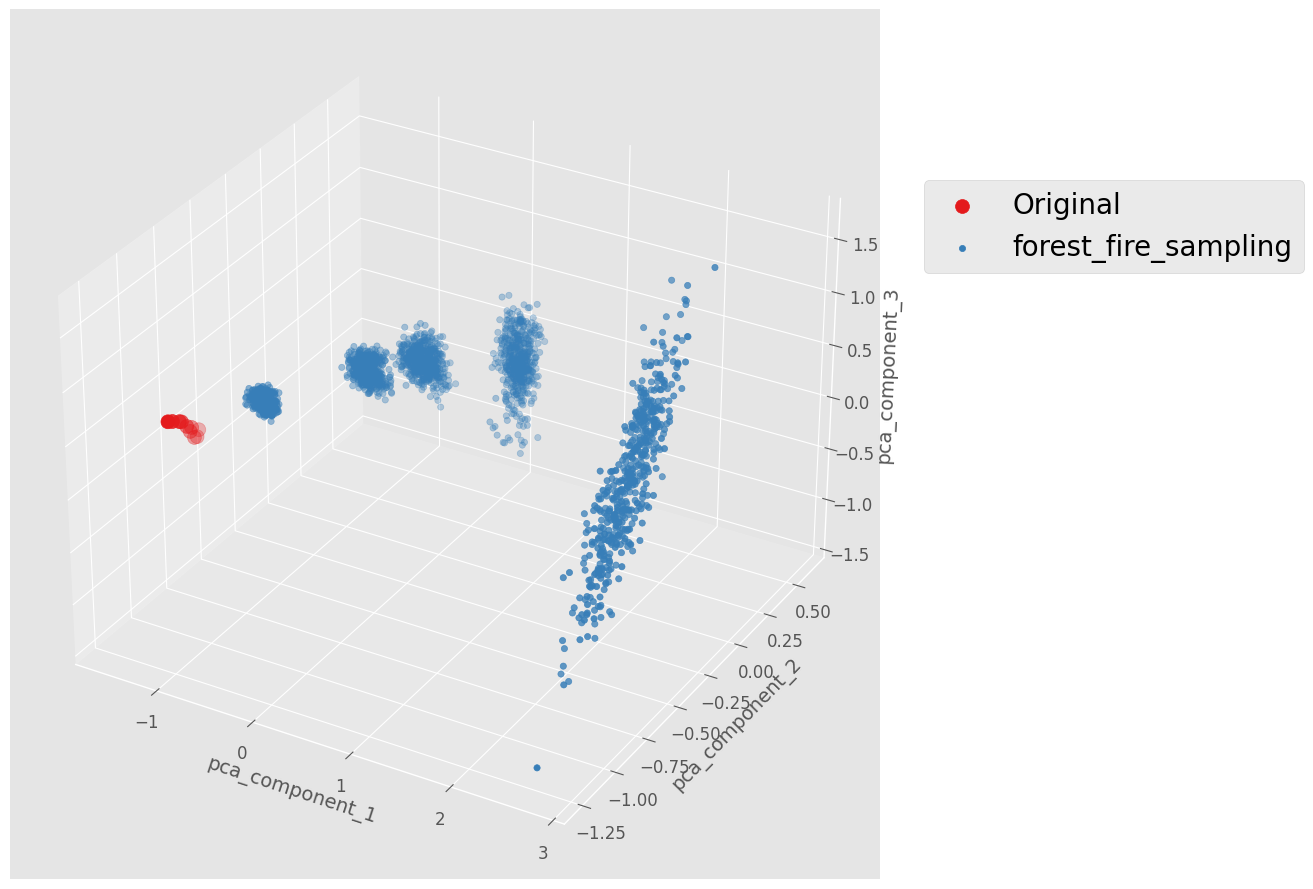

In [12]:
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

plt.rc('xtick', labelsize = 12) 
fig = plt.figure(figsize = (14, 9))
ax = fig.add_subplot(111, projection='3d')

ax.set_prop_cycle(color=plt.cm.Set1.colors)

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']


for method in m.unique():  
    if method == "Original":
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method, s = 100)
    else:
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method)

ax.legend(fontsize = 20, bbox_to_anchor=(1.05, 0.75), 
            loc="center left", borderaxespad=0.)

ax.set_xlabel('pca_component_1', fontsize = 14)
ax.set_ylabel('pca_component_2', fontsize = 14)
ax.set_zlabel('pca_component_3', fontsize = 14)

plt.tight_layout()
plt.show()

## $p$=0.5

In [2]:
graph_list = []

av_degree = 10  
m = int(av_degree / 2)
random.seed(42)

for i in range(10):
    seed = random.randint(1, 1000000)
    G = nx.barabasi_albert_graph(n = 1000, m = m, seed=seed)
    graph_list.append(G)

In [3]:
och = st.Samnet_ochestrator(graph_list=graph_list)

In [4]:
och.sample_genesis(sampling_methods_list=[forest_fire_sampling], 
                    sample_sizes=[100,250,400,500,750], runs=50)

Sampling Graphs: 100%|██████████| 2500/2500 [00:02<00:00, 848.54it/s] 


In [5]:
#func_list = [degree_info]

func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics):
        func_list.append(obj)

In [6]:
func_list.pop(9)
func_list.pop(8)
func_list.pop(12)
func_list.pop(12)

<function samnet.metrics.spectral_distance_info(graph, shannon_bin=0.1, n_moments=1, *args, **kwargs)>

In [7]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/ff_serial/swp/')

Metric 13/13 (transitivity): 100%|██████████| 2510/2510 [00:01<00:00, 2043.52it/s]


,graph_id,sampling_method,sample_size,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,betweenness_info_moment_4,betweenness_info_shannon,...,kcore_info_moment_3,kcore_info_moment_4,kcore_info_shannon,local_efficiency,pagerank_info_moment_1,pagerank_info_moment_2,pagerank_info_moment_3,pagerank_info_moment_4,pagerank_info_shannon,transitivity
0,0,Original,1000,-0.063850,2.968539,0.001972,0.000050,0.000003,2.213578e-07,0.000000,...,125.000000,625.000000,0.000000,0.057844,0.001000,0.000002,7.577125e-09,5.095966e-11,0.0,0.031697
1,1,Original,1000,-0.050857,2.974767,0.001979,0.000057,0.000005,5.176923e-07,0.020814,...,125.000000,625.000000,0.000000,0.062587,0.001000,0.000002,8.182398e-09,6.564935e-11,0.0,0.033424
2,2,Original,1000,-0.068383,2.990032,0.001994,0.000038,0.000002,7.878403e-08,0.000000,...,125.000000,625.000000,0.000000,0.046354,0.001000,0.000002,5.946987e-09,3.132128e-11,0.0,0.028673
3,3,Original,1000,-0.066000,2.969746,0.001974,0.000049,0.000003,2.277131e-07,0.000000,...,125.000000,625.000000,0.000000,0.056403,0.001000,0.000002,7.354968e-09,4.884505e-11,0.0,0.030103
4,4,Original,1000,-0.056677,2.982727,0.001987,0.000045,0.000003,1.787958e-07,0.000000,...,125.000000,625.000000,0.000000,0.049750,0.001000,0.000002,6.486866e-09,3.821083e-11,0.0,0.028722
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2505,9,forest_fire_sampling,750,-0.036586,2.968313,0.002631,0.000065,0.000004,2.912589e-07,0.000000,...,117.434667,580.344000,0.587386,0.056657,0.001333,0.000003,1.311769e-08,9.155477e-11,0.0,0.035949
2506,9,forest_fire_sampling,750,-0.022690,2.981301,0.002649,0.000063,0.000004,2.823333e-07,0.014657,...,117.533333,580.810667,0.581303,0.052247,0.001333,0.000003,1.224770e-08,8.209714e-11,0.0,0.035468
2507,9,forest_fire_sampling,750,-0.024376,2.977855,0.002644,0.000063,0.000004,2.575935e-07,0.000000,...,117.250667,578.746667,0.587089,0.055408,0.001333,0.000003,1.232861e-08,8.183497e-11,0.0,0.036704
2508,9,forest_fire_sampling,750,-0.025449,2.983996,0.002652,0.000065,0.000004,2.838607e-07,0.014657,...,115.781333,570.509333,0.672528,0.052742,0.001333,0.000003,1.252599e-08,8.403436e-11,0.0,0.035609


In [8]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/ff_serial/swp/', output_filename='combined_metrics_p05.csv'
)

Successfully combined 13 files into 'data/ff_serial/swp/combined_metrics_p05.csv' (2510 rows, 44 columns).


In [9]:
df = pd.read_csv('data/ff_serial/combined_metrics_p05.csv')

In [10]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 86.0%
PCA Component 2 EVR: 6.6%
PCA Component 3 EVR: 3.7%


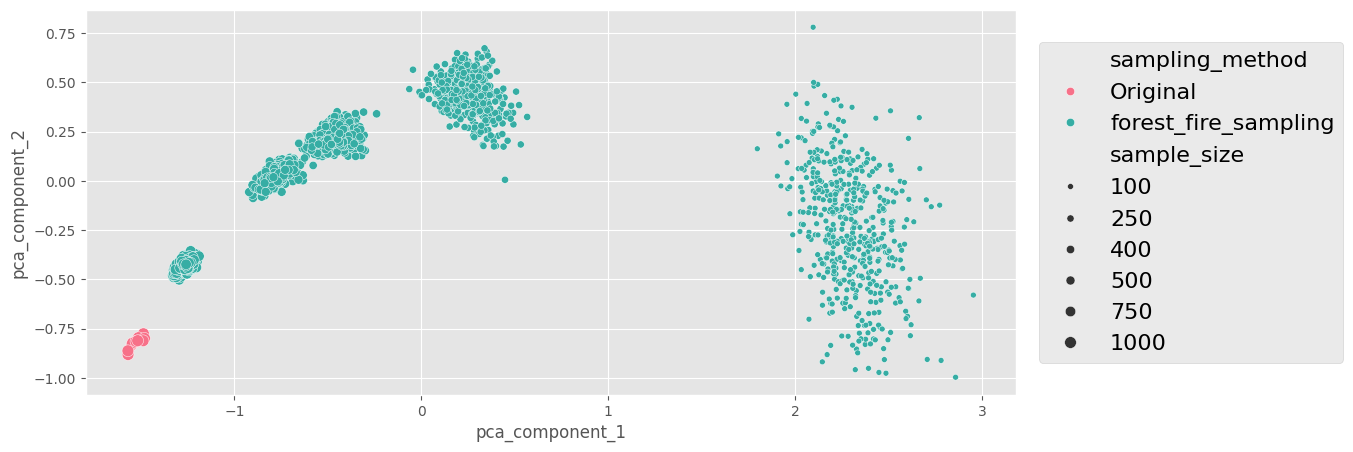

In [11]:
plt.style.use('ggplot')
plt.figure(figsize=(12,5))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                size = "sample_size", 
                hue = "sampling_method", 
                palette = "husl")
plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
            loc="center left", borderaxespad=0.)

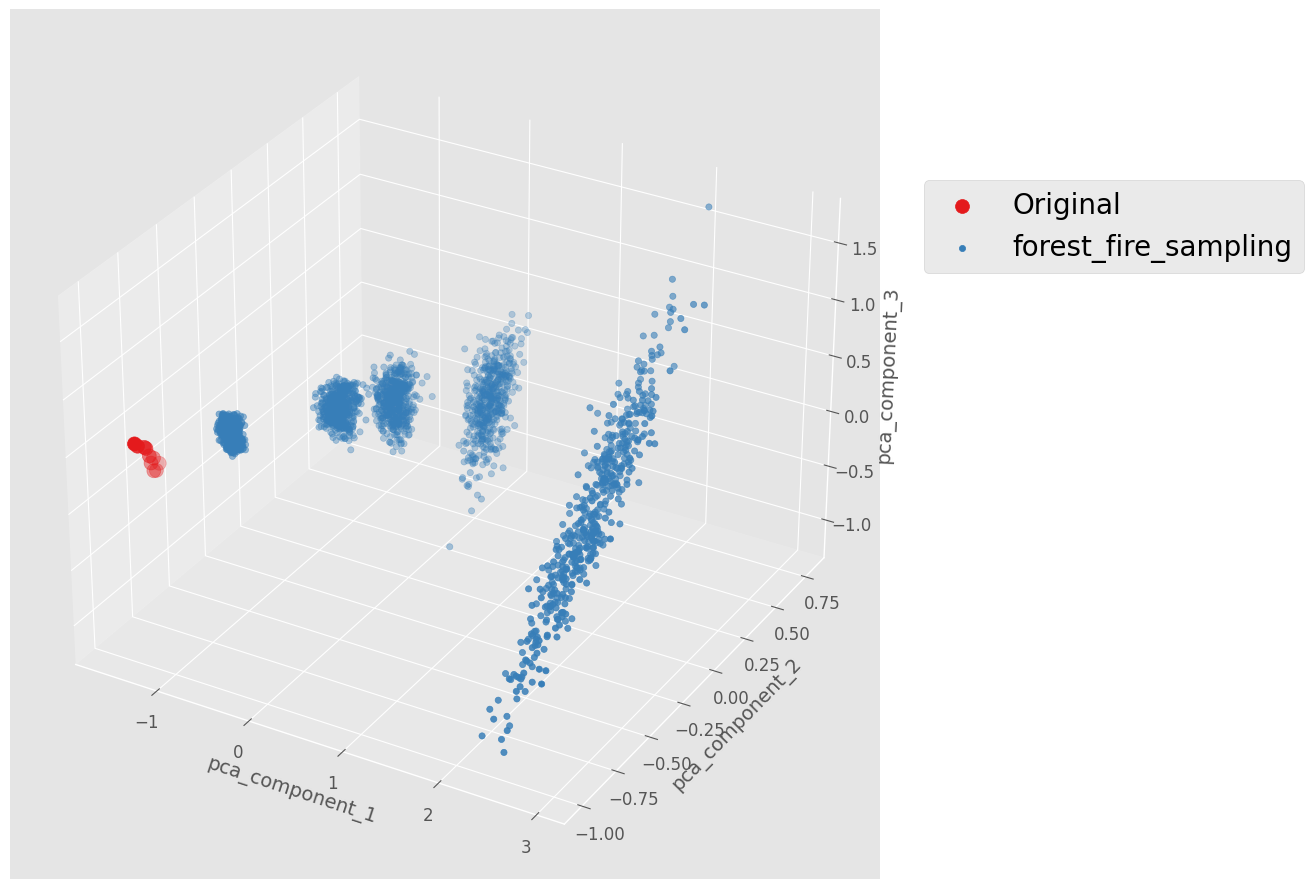

In [12]:
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

plt.rc('xtick', labelsize = 12) 
fig = plt.figure(figsize = (14, 9))
ax = fig.add_subplot(111, projection='3d')

ax.set_prop_cycle(color=plt.cm.Set1.colors)

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']


for method in m.unique():  
    if method == "Original":
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method, s = 100)
    else:
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method)

ax.legend(fontsize = 20, bbox_to_anchor=(1.05, 0.75), 
            loc="center left", borderaxespad=0.)

ax.set_xlabel('pca_component_1', fontsize = 14)
ax.set_ylabel('pca_component_2', fontsize = 14)
ax.set_zlabel('pca_component_3', fontsize = 14)

plt.tight_layout()
plt.show()

## $p$=0.7

In [2]:
graph_list = []

av_degree = 10  
m = int(av_degree / 2)
random.seed(42)

for i in range(10):
    seed = random.randint(1, 1000000)
    G = nx.barabasi_albert_graph(n = 1000, m = m, seed=seed)
    graph_list.append(G)

In [3]:
och = st.Samnet_ochestrator(graph_list=graph_list)

In [4]:
och.sample_genesis(sampling_methods_list=[forest_fire_sampling], 
                    sample_sizes=[100,250,400,500,750], runs=50)

Sampling Graphs: 100%|██████████| 2500/2500 [00:02<00:00, 863.26it/s] 


In [5]:
#func_list = [degree_info]

func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics):
        func_list.append(obj)

In [6]:
func_list.pop(9)
func_list.pop(8)
func_list.pop(12)
func_list.pop(12)

<function samnet.metrics.spectral_distance_info(graph, shannon_bin=0.1, n_moments=1, *args, **kwargs)>

In [7]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/ff_serial/swp/')

Metric 13/13 (transitivity): 100%|██████████| 2510/2510 [00:01<00:00, 2004.36it/s]


,graph_id,sampling_method,sample_size,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,betweenness_info_moment_4,betweenness_info_shannon,...,kcore_info_moment_3,kcore_info_moment_4,kcore_info_shannon,local_efficiency,pagerank_info_moment_1,pagerank_info_moment_2,pagerank_info_moment_3,pagerank_info_moment_4,pagerank_info_shannon,transitivity
0,0,Original,1000,-0.063850,2.968539,0.001972,0.000050,0.000003,2.213578e-07,0.000000,...,125.000000,625.000000,0.000000,0.057844,0.001000,0.000002,7.577125e-09,5.095966e-11,0.0,0.031697
1,1,Original,1000,-0.050857,2.974767,0.001979,0.000057,0.000005,5.176923e-07,0.020814,...,125.000000,625.000000,0.000000,0.062587,0.001000,0.000002,8.182398e-09,6.564935e-11,0.0,0.033424
2,2,Original,1000,-0.068383,2.990032,0.001994,0.000038,0.000002,7.878403e-08,0.000000,...,125.000000,625.000000,0.000000,0.046354,0.001000,0.000002,5.946987e-09,3.132128e-11,0.0,0.028673
3,3,Original,1000,-0.066000,2.969746,0.001974,0.000049,0.000003,2.277131e-07,0.000000,...,125.000000,625.000000,0.000000,0.056403,0.001000,0.000002,7.354968e-09,4.884505e-11,0.0,0.030103
4,4,Original,1000,-0.056677,2.982727,0.001987,0.000045,0.000003,1.787958e-07,0.000000,...,125.000000,625.000000,0.000000,0.049750,0.001000,0.000002,6.486866e-09,3.821083e-11,0.0,0.028722
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2505,9,forest_fire_sampling,750,-0.032511,2.980023,0.002647,0.000062,0.000004,2.975917e-07,0.014657,...,116.678667,575.769333,0.621670,0.055019,0.001333,0.000003,1.248059e-08,8.524777e-11,0.0,0.036234
2506,9,forest_fire_sampling,750,-0.047008,2.968043,0.002631,0.000065,0.000004,2.681281e-07,0.000000,...,115.188000,566.886667,0.704046,0.058187,0.001333,0.000003,1.353525e-08,9.382060e-11,0.0,0.035566
2507,9,forest_fire_sampling,750,-0.035835,2.972322,0.002637,0.000063,0.000003,2.527918e-07,0.000000,...,115.832000,570.650667,0.670777,0.058228,0.001333,0.000003,1.265672e-08,8.397312e-11,0.0,0.036712
2508,9,forest_fire_sampling,750,-0.037340,2.966636,0.002629,0.000062,0.000003,2.208802e-07,0.000000,...,116.596000,575.337333,0.634479,0.053842,0.001333,0.000003,1.261774e-08,8.229550e-11,0.0,0.035239


In [8]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/ff_serial/swp/', output_filename='combined_metrics_p07.csv'
)

Successfully combined 13 files into 'data/ff_serial/swp/combined_metrics_p07.csv' (2510 rows, 44 columns).


In [9]:
df = pd.read_csv('data/ff_serial/combined_metrics_p07.csv')

In [10]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 86.0%
PCA Component 2 EVR: 6.7%
PCA Component 3 EVR: 3.7%


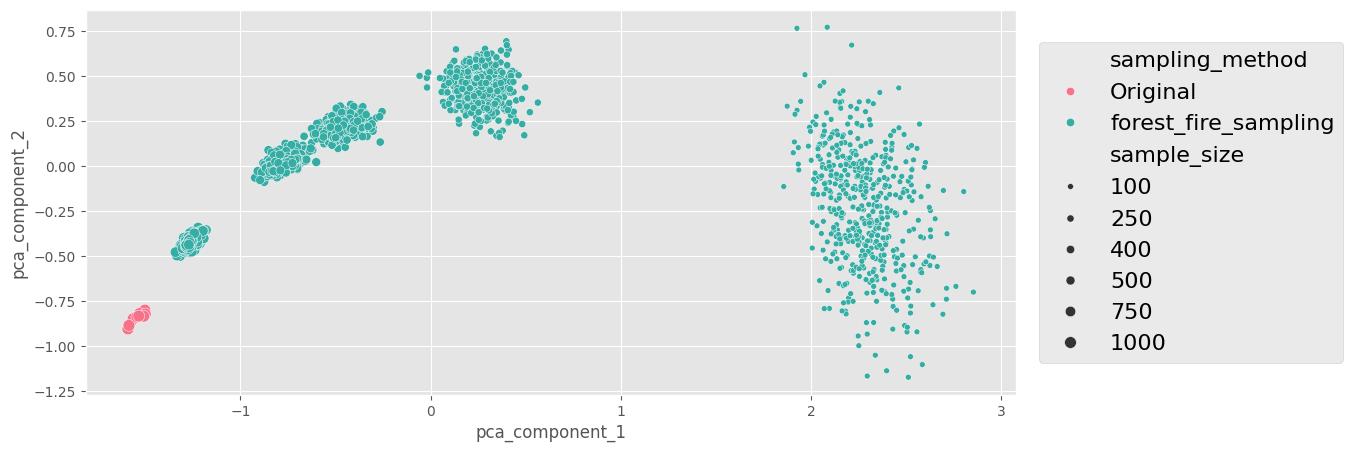

In [11]:
plt.style.use('ggplot')
plt.figure(figsize=(12,5))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                size = "sample_size", 
                hue = "sampling_method", 
                palette = "husl")
plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
            loc="center left", borderaxespad=0.)

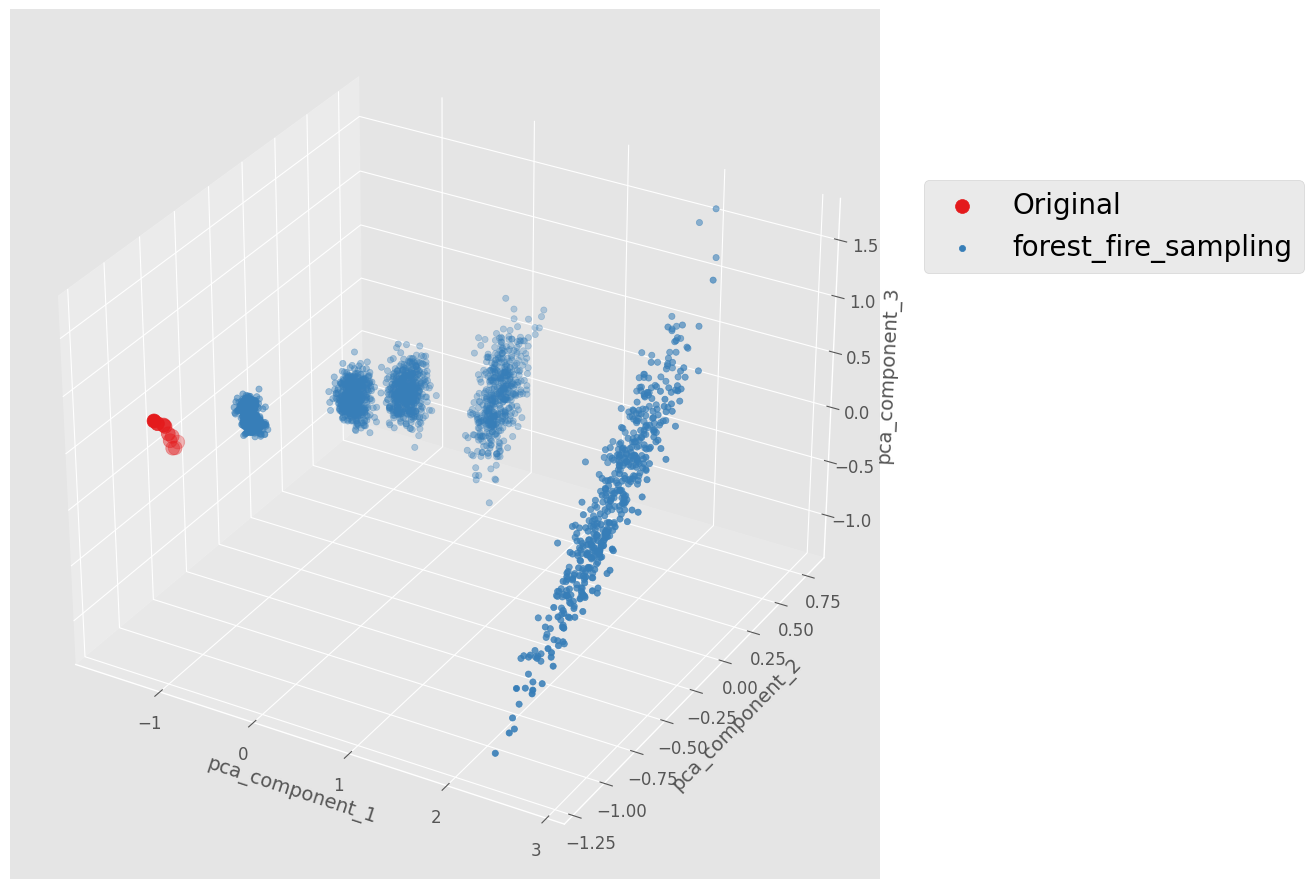

In [12]:
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

plt.rc('xtick', labelsize = 12) 
fig = plt.figure(figsize = (14, 9))
ax = fig.add_subplot(111, projection='3d')

ax.set_prop_cycle(color=plt.cm.Set1.colors)

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']


for method in m.unique():  
    if method == "Original":
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method, s = 100)
    else:
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method)

ax.legend(fontsize = 20, bbox_to_anchor=(1.05, 0.75), 
            loc="center left", borderaxespad=0.)

ax.set_xlabel('pca_component_1', fontsize = 14)
ax.set_ylabel('pca_component_2', fontsize = 14)
ax.set_zlabel('pca_component_3', fontsize = 14)

plt.tight_layout()
plt.show()

## $p$=0.9

In [2]:
graph_list = []

av_degree = 10  
m = int(av_degree / 2)
random.seed(42)

for i in range(10):
    seed = random.randint(1, 1000000)
    G = nx.barabasi_albert_graph(n = 1000, m = m, seed=seed)
    graph_list.append(G)

In [3]:
och = st.Samnet_ochestrator(graph_list=graph_list)

In [4]:
och.sample_genesis(sampling_methods_list=[forest_fire_sampling], 
                    sample_sizes=[100,250,400,500,750], runs=50)

Sampling Graphs: 100%|██████████| 2500/2500 [00:02<00:00, 997.32it/s] 


In [5]:
#func_list = [degree_info]

func_list = []
for i in dir(st.metrics):
    obj = getattr(st.metrics, i)
    if inspect.isfunction(obj) and i not in dir(st.statistics):
        func_list.append(obj)

In [6]:
func_list.pop(9)
func_list.pop(8)
func_list.pop(12)
func_list.pop(12)

<function samnet.metrics.spectral_distance_info(graph, shannon_bin=0.1, n_moments=1, *args, **kwargs)>

In [7]:
och.sample_describer(functions_list=func_list, n_moments=4, max_workers=18, checkpoint_dir='data/ff_serial/swp/')

Metric 13/13 (transitivity): 100%|██████████| 2510/2510 [00:07<00:00, 323.25it/s]


,graph_id,sampling_method,sample_size,assortativity,avg_spl,betweenness_info_moment_1,betweenness_info_moment_2,betweenness_info_moment_3,betweenness_info_moment_4,betweenness_info_shannon,...,kcore_info_moment_3,kcore_info_moment_4,kcore_info_shannon,local_efficiency,pagerank_info_moment_1,pagerank_info_moment_2,pagerank_info_moment_3,pagerank_info_moment_4,pagerank_info_shannon,transitivity
0,0,Original,1000,-0.063850,2.968539,0.001972,0.000050,0.000003,2.213578e-07,0.000000,...,125.000000,625.000000,0.000000,0.057844,0.001000,0.000002,7.577125e-09,5.095966e-11,0.0,0.031697
1,1,Original,1000,-0.050857,2.974767,0.001979,0.000057,0.000005,5.176923e-07,0.020814,...,125.000000,625.000000,0.000000,0.062587,0.001000,0.000002,8.182398e-09,6.564935e-11,0.0,0.033424
2,2,Original,1000,-0.068383,2.990032,0.001994,0.000038,0.000002,7.878403e-08,0.000000,...,125.000000,625.000000,0.000000,0.046354,0.001000,0.000002,5.946987e-09,3.132128e-11,0.0,0.028673
3,3,Original,1000,-0.066000,2.969746,0.001974,0.000049,0.000003,2.277131e-07,0.000000,...,125.000000,625.000000,0.000000,0.056403,0.001000,0.000002,7.354968e-09,4.884505e-11,0.0,0.030103
4,4,Original,1000,-0.056677,2.982727,0.001987,0.000045,0.000003,1.787958e-07,0.000000,...,125.000000,625.000000,0.000000,0.049750,0.001000,0.000002,6.486866e-09,3.821083e-11,0.0,0.028722
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2505,9,forest_fire_sampling,750,-0.050009,2.973426,0.002638,0.000064,0.000004,2.439154e-07,0.000000,...,114.489333,562.657333,0.732264,0.054134,0.001333,0.000003,1.334306e-08,8.932991e-11,0.0,0.035292
2506,9,forest_fire_sampling,750,-0.053444,2.977741,0.002644,0.000064,0.000003,2.348189e-07,0.000000,...,113.394667,556.432000,0.790931,0.056155,0.001333,0.000003,1.363445e-08,9.305997e-11,0.0,0.035562
2507,9,forest_fire_sampling,750,-0.061395,2.957618,0.002617,0.000069,0.000004,3.305201e-07,0.014657,...,111.526667,544.996000,0.855947,0.059302,0.001333,0.000003,1.480929e-08,1.093012e-10,0.0,0.035433
2508,9,forest_fire_sampling,750,-0.052536,2.962172,0.002623,0.000066,0.000004,2.690511e-07,0.000000,...,115.114667,566.506667,0.707811,0.057143,0.001333,0.000003,1.365931e-08,9.329766e-11,0.0,0.035390


In [8]:
df_all = och.combine_stage_checkpoints(
    checkpoint_dir='data/ff_serial/swp/', output_filename='combined_metrics_p09.csv'
)

Successfully combined 13 files into 'data/ff_serial/swp/combined_metrics_p09.csv' (2510 rows, 44 columns).


In [9]:
df = pd.read_csv('data/ff_serial/combined_metrics_p09.csv')

In [10]:
df_pca = st.pca_table_processing(df=df, components=3, drop_columns=['graph_id', 'sampling_method', 'sample_size'])

Explained Variance Ratio (EVR):

PCA Component 1 EVR: 86.5%
PCA Component 2 EVR: 5.9%
PCA Component 3 EVR: 3.8%


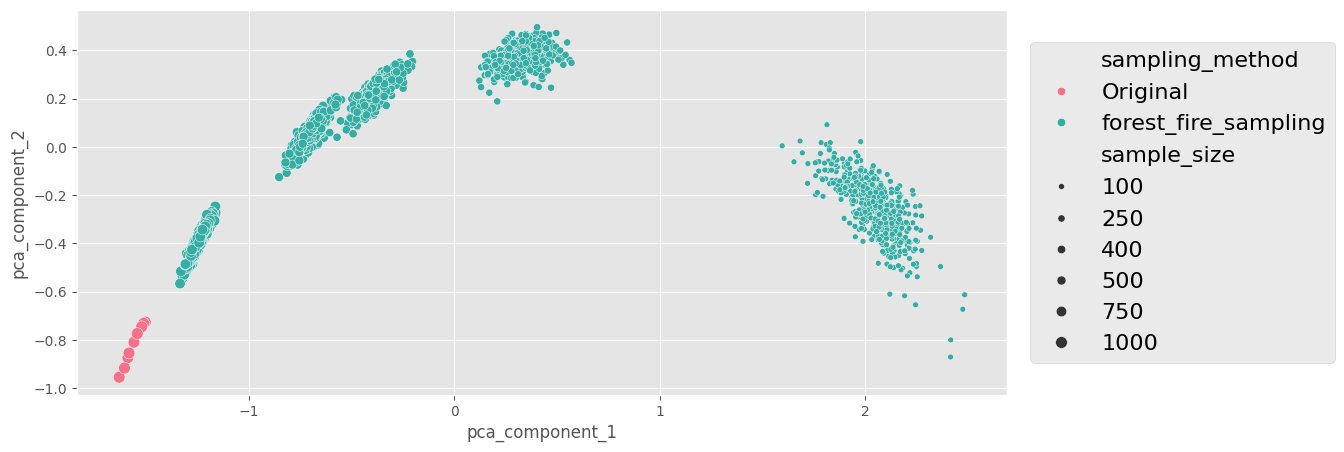

In [11]:
plt.style.use('ggplot')
plt.figure(figsize=(12,5))
sns.scatterplot(data=df_pca, 
                x="pca_component_1", 
                y="pca_component_2", 
                size = "sample_size", 
                hue = "sampling_method", 
                palette = "husl")
plt.legend(fontsize=16, bbox_to_anchor=(1.025, 0.5), 
            loc="center left", borderaxespad=0.)

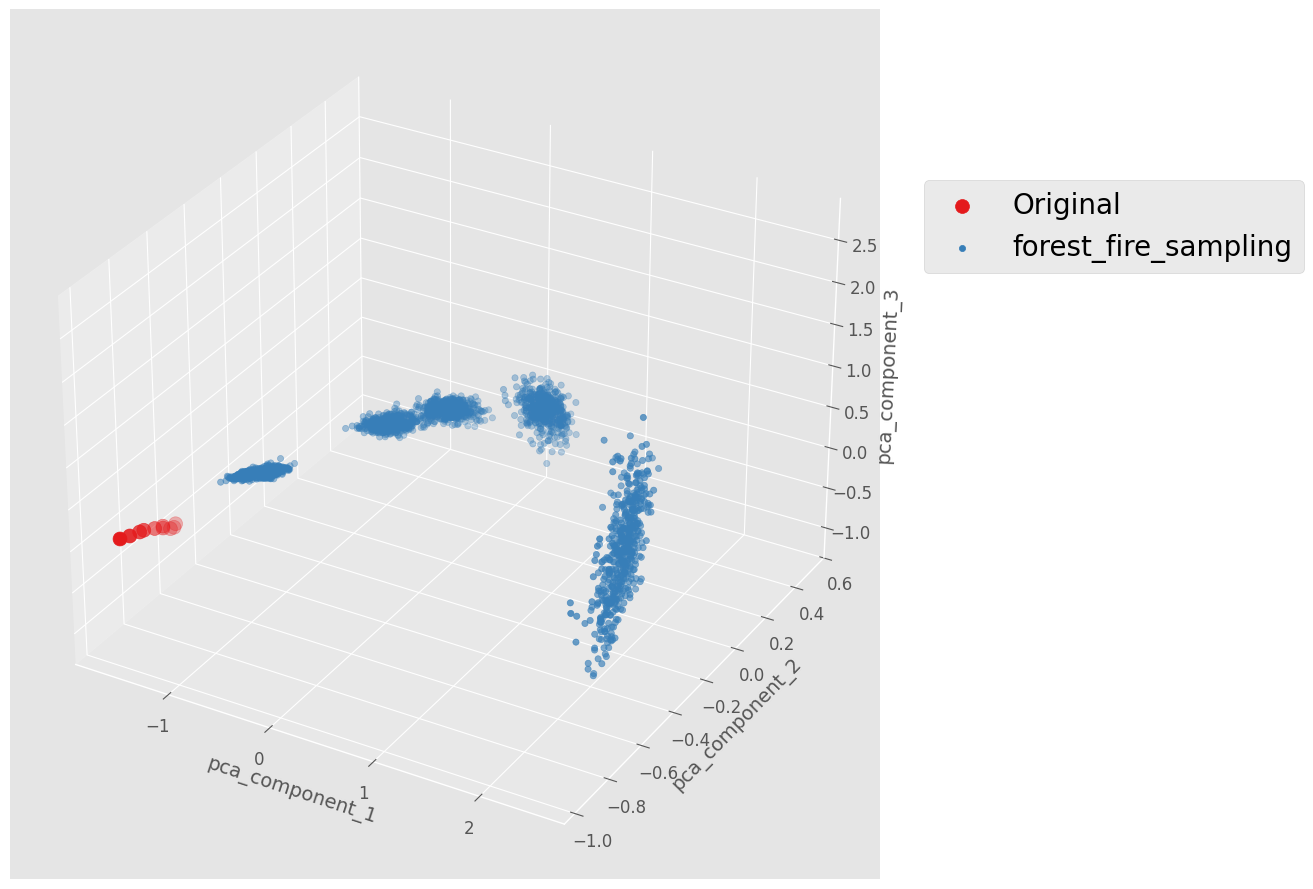

In [12]:
m = df_pca["sampling_method"]
sizes = df_pca["sample_size"]

plt.rc('xtick', labelsize = 12) 
fig = plt.figure(figsize = (14, 9))
ax = fig.add_subplot(111, projection='3d')

ax.set_prop_cycle(color=plt.cm.Set1.colors)

xs = df_pca['pca_component_1']
ys = df_pca['pca_component_2']
zs = df_pca['pca_component_3']


for method in m.unique():  
    if method == "Original":
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method, s = 100)
    else:
        ax.scatter(xs[m.values == method], ys[m.values == method], zs[m.values == method], label = method)

ax.legend(fontsize = 20, bbox_to_anchor=(1.05, 0.75), 
            loc="center left", borderaxespad=0.)

ax.set_xlabel('pca_component_1', fontsize = 14)
ax.set_ylabel('pca_component_2', fontsize = 14)
ax.set_zlabel('pca_component_3', fontsize = 14)

plt.tight_layout()
plt.show()